<a href="https://colab.research.google.com/github/ms24144-create/Group19_IDC409-Faculty-profiles-web-scraper-/blob/main/Project_IDC409.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GROUP-19 PROJECT

In [ ]:
# project configuration
from pathlib import Path
from types import SimpleNamespace

BASE_URL = "https://www.iisermohali.ac.in"

config = SimpleNamespace(
    BASE_URL=BASE_URL,
    DIRECTORY_URL=f"{BASE_URL}/people",

    USER_AGENT=("FacultyProfileExplorer/0.1 "
                "(student course project; contact: kartiksa563@gmail.com)"),
    REQUEST_TIMEOUT=20,
    DELAY_BETWEEN_REQUESTS=2.0,
    # save files under the data folder
    RAW_DIR=Path.cwd() / "data" / "raw",
)
config.HEADERS = {"User-Agent": config.USER_AGENT}
print("Saving files under:", config.RAW_DIR)

Saving files under: /content/data/raw


In [ ]:
from collections import Counter
from urllib.parse import urljoin, urlparse
from urllib.robotparser import RobotFileParser

import requests
from bs4 import BeautifulSoup


# check the table headers
EXPECTED_HEADER = ["name", "department", "designation", "email"]


def clean_text(tag):
    """Return the text inside an HTML tag with all extra whitespace removed.

    str.split() with no argument splits on ANY whitespace (spaces, tabs,
    newlines, non-breaking spaces), and " ".join() glues the words back
    together with single spaces.
    """
    return " ".join(tag.get_text().split())


def robots_allows(url):
    """Check the site's robots.txt and say whether our bot may fetch `url`."""
    robots_url = urljoin(config.BASE_URL, "/robots.txt")
    response = requests.get(robots_url, headers=config.HEADERS,
                            timeout=config.REQUEST_TIMEOUT)

    if response.status_code == 404:
        print("  No robots.txt found (HTTP 404): the site publishes no crawler rules.")
        return True

    response.raise_for_status()              # handle errors
    rules = RobotFileParser()
    rules.parse(response.text.splitlines())  # read the file line by line
    allowed = rules.can_fetch(config.USER_AGENT, url)
    print(f"  robots.txt says fetching {url} is {'ALLOWED' if allowed else 'NOT ALLOWED'}")
    return allowed


def fetch_html(url):
    """Download one web page and return its HTML as text."""
    response = requests.get(url, headers=config.HEADERS,
                            timeout=config.REQUEST_TIMEOUT)
    response.raise_for_status()   # check for errors
    return response.text


def describe_tables(soup):
    """Debug helper: print the header row of every table on the page."""
    for number, table in enumerate(soup.find_all("table"), start=1):
        first_row = table.find("tr")
        header = [clean_text(c) for c in first_row.find_all(["th", "td"])] if first_row else []
        print(f"  table {number}: {header}")


def find_faculty_table(soup):
    """Return the <table> whose header is Name | Department | Designation | Email."""
    for table in soup.find_all("table"):
        first_row = table.find("tr")
        if first_row is None:
            continue
        header = [clean_text(c).lower() for c in first_row.find_all(["th", "td"])]
        if header == EXPECTED_HEADER:
            return table
    return None   # return none if not found


def department_from_url(profile_url):
    """'.../faculty/dbs/indranil' -> 'DBS'. Returns None if the URL has no such part."""
    if not profile_url:
        return None
    parts = urlparse(profile_url).path.strip("/").split("/")
    if len(parts) >= 3 and parts[0] == "faculty":
        return parts[1].upper()
    return None


def parse_faculty_table(table):
    """Turn each table row into a dictionary (one dictionary = one faculty member)."""
    records = []
    for row in table.find_all("tr")[1:]:          # skip the header row
        cells = row.find_all("td")
        if len(cells) < 4:                         # skip incomplete rows
            continue

        link = cells[0].find("a")                  # get the profile link
        if link is not None and link.get("href"):
            profile_url = urljoin(config.BASE_URL, link["href"])   # get the full url
        else:
            profile_url = None

        records.append({
            "name": clean_text(cells[0]),
            "department_code": clean_text(cells[1]),
            "designation": clean_text(cells[2]),
            "profile_url": profile_url,
            "url_department_code": department_from_url(profile_url),
            # email column is not stored
        })
    return records


def print_summary(records):
    """Print simple counts so we can check the scrape with our own eyes."""
    print(f"\nRows parsed: {len(records)}")

    print("\nRows per department (from the table):")
    for code, count in sorted(Counter(r["department_code"] for r in records).items()):
        print(f"  {code}: {count}")

    print("\nRows per designation:")
    for title, count in Counter(r["designation"] for r in records).most_common():
        print(f"  {title}: {count}")

    no_link = [r["name"] for r in records if r["profile_url"] is None]
    print(f"\nRows without a profile link: {len(no_link)} {no_link}")

    mismatches = [r for r in records
                  if r["url_department_code"] not in (None, r["department_code"])]
    print(f"Rows where table department != department in the URL: {len(mismatches)}")
    for r in mismatches:
        print(f"  {r['name']}: table says {r['department_code']}, URL says {r['url_department_code']}")

    print("\nFirst 5 rows:")
    for r in records[:5]:
        print(f"  {r['name']} | {r['department_code']} | {r['designation']} | {r['profile_url']}")


def main():
    print("Step 1: checking robots.txt ...")
    if not robots_allows(config.DIRECTORY_URL):
        print("Stopping: robots.txt does not allow this page. Ask your instructor.")
        return

    print("Step 2: downloading the directory page (1 request) ...")
    html = fetch_html(config.DIRECTORY_URL)

    # Save a copy of the page
    config.RAW_DIR.mkdir(parents=True, exist_ok=True)
    snapshot = config.RAW_DIR / "directory_snapshot.html"
    snapshot.write_text(html, encoding="utf-8")
    print(f"  Saved a copy to {snapshot}")

    print("Step 3: finding the faculty table ...")
    soup = BeautifulSoup(html, "lxml")
    table = find_faculty_table(soup)
    if table is None:
        print("Could not find a table with header Name | Department | Designation | Email.")
        print("Tables that DO exist on the page:")
        describe_tables(soup)
        print("The page may have changed, or its rows may be loaded by JavaScript.")
        return

    records = parse_faculty_table(table)
    print_summary(records)

In [ ]:
main()

Step 1: checking robots.txt ...
  robots.txt says fetching https://www.iisermohali.ac.in/people is ALLOWED
Step 2: downloading the directory page (1 request) ...
  Saved a copy to /content/data/raw/directory_snapshot.html
Step 3: finding the faculty table ...

Rows parsed: 122

Rows per department (from the table):
  DBS: 28
  DCS: 25
  DMS: 21
  DPS: 28
  EES: 12
  HSS: 8

Rows per designation:
  Assistant Professor: 44
  Associate Professor: 40
  Professor: 38

Rows without a profile link: 0 []
Rows where table department != department in the URL: 2
  Krishnendu Gongopadhyay: table says DMS, URL says HSS
  Samrat Mukhopadhyay: table says DBS, URL says DCS

First 5 rows:
  Abhik Ganguli | DMS | Assistant Professor | https://www.iisermohali.ac.in/faculty/dms/aganguli
  Abhishek Chaudhuri | DPS | Professor | https://www.iisermohali.ac.in/faculty/dps/abhishek
  Adrene Freeda Dcruz | HSS | Associate Professor | https://www.iisermohali.ac.in/faculty/hss/adrene
  Alok Maharana | DMS | Assis

In [ ]:
# DAY 2 / CELL 3 -- functions to read a profile page
import re
import time
from datetime import datetime, timezone

import pandas as pd


def get_text_lines(element):
    """Return the text of an HTML element as a list of clean, NON-EMPTY lines.

    get_text("\n") puts a newline between every separate piece of text inside
    the element, so <h2>Research Area</h2><p>Topology</p> becomes two lines.
    Then we clean each line and drop the empty ones.
    """
    pieces = (" ".join(piece.split()) for piece in element.get_text("\n").split("\n"))
    return [piece for piece in pieces if piece]


# map tab names to column names
TAB_TO_COLUMN = {
    "career highlights": "career_text",
    "awards & recognitions": "awards_text",
    "publications": "publications_text",
}
AREA_LABEL = re.compile(r"research areas?:?", re.IGNORECASE)
INTEREST_LABEL = re.compile(r"research interests?:?", re.IGNORECASE)

# find tab links
TAB_LINK_SELECTOR = 'a[href^="#sppb-tab-"]'


def find_tab_panes(soup):
    """Return {tab title in lower case: the HTML box holding that tab's content}."""
    panes = {}
    for link in soup.select(TAB_LINK_SELECTOR):
        pane = soup.find(id=link["href"][1:])        # get the tab id
        if pane is not None:
            panes[clean_text(link).lower()] = pane
    return panes


def _first_index(lines, pattern):
    """Position of the first line that is exactly a label like 'Research Area', else None."""
    for i, line in enumerate(lines):
        if pattern.fullmatch(line):
            return i
    return None


def split_research(lines):
    """From the Research tab's lines, return (research_area, research_interests)."""
    area_i = _first_index(lines, AREA_LABEL)
    interest_i = _first_index(lines, INTEREST_LABEL)

    def text_after(start, other):
        """Join the lines after `start` up to the other label (or the end)."""
        if start is None:
            return None
        end = other if (other is not None and other > start) else len(lines)
        return " ".join(lines[start + 1:end]) or None

    return text_after(area_i, interest_i), text_after(interest_i, area_i)


def find_department_line(lines):
    """Find the 'Department of ...' line and the line just before it (the designation)."""
    for i, line in enumerate(lines):
        if re.match(r"department of ", line, re.IGNORECASE):
            return line, (lines[i - 1] if i > 0 else None)
    return None, None


def tab_text(pane, joiner=" | "):
    """All text in a tab; lines are glued together with `joiner`. None if empty or a placeholder."""
    text = joiner.join(get_text_lines(pane))
    if not text or "{bibtex}" in text:
        return None
    return text


def parse_profile(html):
    """Parse one profile page into a dictionary of columns (missing values = None)."""
    soup = BeautifulSoup(html, "lxml")
    for tag in soup(["script", "style"]):            # remove scripts and styles
        tag.decompose()

    department, designation = find_department_line(get_text_lines(soup))
    panes = find_tab_panes(soup)

    result = {
        "page_title": clean_text(soup.title) if soup.title else None,
        "designation_on_profile": designation,
        "department_on_profile": department,
        "research_area": None,
        "research_interests": None,
        "research_tab_text": None,
        "career_text": None,
        "awards_text": None,
        "publications_text": None,
        "tabs_found": " | ".join(panes) or None,
        "parse_mode": "tabs" if panes else "no_tabs",
    }

    for title, pane in panes.items():
        if title == "research":
            lines = get_text_lines(pane)
            result["research_tab_text"] = " ".join(lines) or None
            result["research_area"], result["research_interests"] = split_research(lines)
        elif title in TAB_TO_COLUMN:
            # separate career and award entries
            # join publication text with spaces
            joiner = " " if title == "publications" else " | "
            result[TAB_TO_COLUMN[title]] = tab_text(pane, joiner)

    return result


def describe_structure(html):
    """'X-ray' of a page: prints the headings and the tab links with the boxes they point to."""
    soup = BeautifulSoup(html, "lxml")
    print("<title>:", clean_text(soup.title) if soup.title else None)

    print("\nFirst headings (h1-h4):")
    for heading in soup.find_all(["h1", "h2", "h3", "h4"])[:12]:
        print(f"  <{heading.name}> {clean_text(heading)[:70]}")

    print("\nTab links and the boxes they point to:")
    links = soup.select(TAB_LINK_SELECTOR)
    if not links:
        print("  (no tab links found)")
    for link in links:
        pane = soup.find(id=link["href"][1:])
        if pane is None:
            where = "box NOT FOUND in the HTML"
        else:
            where = f"<{pane.name} class={pane.get('class')}> with {len(get_text_lines(pane))} text lines"
        print(f"  '{clean_text(link)}' -> {link['href'][:22]}... -> {where}")

In [ ]:
# DAY 2 / CELL 4 -- load data and check results
def load_directory_records():
    """Rebuild the faculty list from the Day 1 snapshot (no new request if it exists)."""
    snapshot = config.RAW_DIR / "directory_snapshot.html"
    if snapshot.exists():
        html = snapshot.read_text(encoding="utf-8")
    else:                                             # download if needed
        html = fetch_html(config.DIRECTORY_URL)
        config.RAW_DIR.mkdir(parents=True, exist_ok=True)
        snapshot.write_text(html, encoding="utf-8")
    table = find_faculty_table(BeautifulSoup(html, "lxml"))
    if table is None:
        raise RuntimeError("Faculty table not found -- run the Day 1 scraper first.")
    return parse_faculty_table(table)


def choose_pilot(records):
    """A small test group: the first 3 people plus every row whose department looks inconsistent."""
    odd = [r for r in records[3:]
           if r["url_department_code"] not in (None, r["department_code"])]
    return records[:3] + odd


def get_profile_html(url):
    """Return (html, downloaded). Re-uses our saved copy if this page was downloaded before."""
    pages_dir = config.RAW_DIR / "profile_pages"
    pages_dir.mkdir(parents=True, exist_ok=True)
    # example profile URL
    cache_file = pages_dir / (url.rstrip("/").split("/faculty/")[-1].replace("/", "_") + ".html")
    if cache_file.exists():
        return cache_file.read_text(encoding="utf-8"), False
    html = fetch_html(url)
    cache_file.write_text(html, encoding="utf-8")
    return html, True


def save_raw_csv(rows, path):
    """Save a list of dictionaries as a CSV file (one dictionary = one row)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(path, index=False, encoding="utf-8")


def scrape_profiles(records, checkpoint_path=None):
    """Visit each profile page politely and return a list of row dictionaries."""
    rows, consecutive_errors = [], 0

    for number, record in enumerate(records, start=1):
        row = dict(record)                            # use existing data
        downloaded = False

        if record["profile_url"] is None:
            row["fetch_status"] = "no_profile_url"
        else:
            try:
                html, downloaded = get_profile_html(record["profile_url"])
                row.update(parse_profile(html))
                row["fetch_status"] = "ok"
                consecutive_errors = 0
            except requests.RequestException as error:
                code = getattr(getattr(error, "response", None), "status_code", "")
                row["fetch_status"] = f"error: {type(error).__name__} {code}".strip()
                consecutive_errors += 1

        row["scraped_at_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
        rows.append(row)
        print(f"  [{number}/{len(records)}] {record['name']}: {row['fetch_status']}")

        if consecutive_errors >= 3:                   # stop after repeated errors
            print("STOPPING: 3 errors in a row. The server may be blocking or struggling. "
                  "Do not retry in a loop; tell your instructor/me.")
            break
        if checkpoint_path is not None and number % 20 == 0:
            save_raw_csv(rows, checkpoint_path)       # save progress every 20 rows
        if downloaded:                                # pause after downloading
            time.sleep(config.DELAY_BETWEEN_REQUESTS)
    return rows


def show_pilot(rows):
    """Print the extracted fields of each pilot row so we can check them by eye."""
    columns = ["department_on_profile", "designation_on_profile", "tabs_found", "research_area",
               "research_interests", "career_text", "awards_text", "publications_text"]
    for row in rows:
        print("-" * 72)
        print(f"{row['name']} | {row['fetch_status']} | parse_mode: {row.get('parse_mode')}")
        for column in columns:
            value = row.get(column)
            print(f"   {column}: {'(missing)' if value is None else str(value)[:110]}")


def quality_report(csv_path):
    """Read the saved CSV back and print simple quality checks."""
    df = pd.read_csv(csv_path)
    print("Rows:", len(df))
    print("\nfetch_status:\n" + df["fetch_status"].value_counts().to_string())
    print("\nparse_mode:\n" + df["parse_mode"].value_counts(dropna=False).to_string())
    print("\n% missing per column:\n" + (df.isna().mean() * 100).round(1).to_string())
    print("\nDirectory department code vs department text on the profile:")
    print(df.groupby(["department_code", "department_on_profile"], dropna=False).size().to_string())

In [ ]:

def profile_pages_allowed(records):
    """One-time robots.txt check for the profile-page URL pattern (/faculty/...)."""
    first_url = next((r["profile_url"] for r in records if r["profile_url"]), None)
    return first_url is not None and robots_allows(first_url)

In [ ]:
# DAY 2 / CELL 5 -- check profile access and inspect one page
records = load_directory_records()
if not profile_pages_allowed(records):
    raise RuntimeError("robots.txt does not allow the profile pages. STOP and ask your instructor.")

sample = records[0]                                  # first faculty member
html, _ = get_profile_html(sample["profile_url"])    # downloads ONCE and reuse
print("Page:", sample["name"], sample["profile_url"], "\n")
describe_structure(html)

  robots.txt says fetching https://www.iisermohali.ac.in/faculty/dms/aganguli is ALLOWED
Page: Abhik Ganguli https://www.iisermohali.ac.in/faculty/dms/aganguli 

<title>: Dr. Abhik Ganguli

First headings (h1-h4):
  <h1> IISER MOHALI
  <h2> Dr. Abhik Ganguli
  <h2> Assistant Professor
  <h2> Department of Mathematical Sciences
  <h2> Research Area
  <h2> Research Interests
  <h3> website policy
  <h3> Connect with us
  <h3> Administrative Sections
  <h3> Campus Facilities
  <h3> Departments
  <h3> committees

Tab links and the boxes they point to:
  'Research' -> #sppb-tab-K4UNjN-oEkkc... -> <div class=['sppb-tab-pane', 'sppb-fade', 'active', 'in']> with 4 text lines
  'Career Highlights' -> #sppb-tab-K4UNjN-oEkkc... -> <div class=['sppb-tab-pane', 'sppb-fade']> with 1 text lines
  'Publications' -> #sppb-tab-K4UNjN-oEkkc... -> <div class=['sppb-tab-pane', 'sppb-fade']> with 18 text lines


In [ ]:
# DAY 2 / CELL 6 -- text a few profiles and check the results
records = load_directory_records()
pilot_rows = scrape_profiles(choose_pilot(records))
show_pilot(pilot_rows)

  [1/5] Abhik Ganguli: ok
  [2/5] Abhishek Chaudhuri: ok
  [3/5] Adrene Freeda Dcruz: ok
  [4/5] Krishnendu Gongopadhyay: ok
  [5/5] Samrat Mukhopadhyay: ok
------------------------------------------------------------------------
Abhik Ganguli | ok | parse_mode: tabs
   department_on_profile: Department of Mathematical Sciences
   designation_on_profile: Assistant Professor
   tabs_found: research | career highlights | publications
   research_area: Number Theory
   research_interests: My research interests are in number theory, particularly in Galois representations and modular forms. Currentl
   career_text: Ph.D., University of Chicago
   awards_text: (missing)
   publications_text: Abhik Ganguli and Suneel Kumar. On the local constancy of certain mod p Galois representations. Research in Nu
------------------------------------------------------------------------
Abhishek Chaudhuri | ok | parse_mode: tabs
   department_on_profile: Department of Physical Sciences
   designation_on_pr

In [ ]:
# DAY 2 / CELL 7 -- run full scrape after checking the pilot
RAW_CSV = config.RAW_DIR / "faculty_raw.csv"
rows = scrape_profiles(records, checkpoint_path=RAW_CSV)
save_raw_csv(rows, RAW_CSV)
print("\nSaved:", RAW_CSV)
quality_report(RAW_CSV)

  [1/122] Abhik Ganguli: ok
  [2/122] Abhishek Chaudhuri: ok
  [3/122] Adrene Freeda Dcruz: ok
  [4/122] Alok Maharana: ok
  [5/122] Ambresh Shivaji: ok
  [6/122] Amar Deep: ok
  [7/122] Amit Kulshrestha: ok
  [8/122] Ananth Venkatesan: ok
  [9/122] Angshuman Roy Choudhury: ok
  [10/122] Anil Kumar Dasanna: ok
  [11/122] Anil Kumar Tripathi: ok
  [12/122] Anoop Ambili: ok
  [13/122] Anu Sabhlok: ok
  [14/122] Arghya Mondal: ok
  [15/122] Arijit Kumar De: ok
  [16/122] Arunika Mukhopadhaya: ok
  [17/122] Arvind: ok
  [18/122] Arvind Kumar Shakya: ok
  [19/122] Baerbel Sinha: ok
  [20/122] Balanarayan Pananghat: ok
  [21/122] Chanchal Kumar: ok
  [22/122] Chandrakant Sharma Aribam: ok
  [23/122] Chandrakanta Ojha: ok
  [24/122] Chetan Tukaram Balwe: ok
  [25/122] Debashis Adhikari: ok
  [26/122] Debdulal Saha: ok
  [27/122] Dipanjan Chakraborty: ok
  [28/122] Eswaraiah Chakali: ok
  [29/122] Goutam Sheet: ok
  [30/122] Harvinder Kaur Jassal: ok
  [31/122] Hasan Mohammad: ok
  [32/122] In

In [ ]:
# DAY 2 / CELL 8 -- save results tp google drive
from google.colab import drive
import shutil

drive.mount("/content/drive")
target = Path("/content/drive/MyDrive/faculty_profile_explorer/data_raw")
target.mkdir(parents=True, exist_ok=True)
shutil.copytree(config.RAW_DIR, target, dirs_exist_ok=True)
print("Copied to", target)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to /content/drive/MyDrive/faculty_profile_explorer/data_raw


In [ ]:
# DAY 3 / CELL 1 -- set up data cleaning functions
import re
import unicodedata

import numpy as np
import pandas as pd

# missing value settings
# mark empty or placeholder values as missing
PLACEHOLDERS = {
    "", "n/a", "na", "nil", "none", "null", "not available", "not applicable",
    "tba", "tbd", "to be updated", "will be updated", "coming soon", "under construction",
}

# map department codes to names
DEPARTMENTS = {
    "DBS": "Biological Sciences",
    "DCS": "Chemical Sciences",
    "DMS": "Mathematical Sciences",
    "DPS": "Physical Sciences",
    "EES": "Earth and Environmental Sciences",
    "HSS": "Humanities and Social Sciences",
}

# manually correct department codes if needed
# document manual corrections.
DEPARTMENT_OVERRIDES = {}

TEXT_COLUMNS = ["name", "designation", "department_on_profile", "designation_on_profile",
                "page_title", "research_area", "research_interests", "research_tab_text",
                "career_text", "awards_text", "publications_text"]
REQUIRED_COLUMNS = ["name", "department_code", "designation", "profile_url"]
PROVENANCE_COLUMNS = ["scraped_at_utc"]
MIN_WORDS_OK = 15

FINAL_COLUMNS = ["faculty_id", "name", "designation", "department_code", "department",
                 "department_code_directory", "dept_conflict", "profile_url",
                 "profile_text", "text_source", "profile_text_words", "text_quality",
                 "research_area", "research_interests", "career_text", "awards_text",
                 "publications_text"]

ZERO_WIDTH = dict.fromkeys(map(ord, "\u200b\u200c\u200d\ufeff"), None)


# step 1: clean text
def clean_text_value(value):
    """Clean ONE cell: normalise Unicode, drop invisible characters, collapse whitespace,
    and turn empty text or placeholder text ('N/A', '--', ...) into a real missing value."""
    if not isinstance(value, str):             # handle missing values
        return np.nan
    text = unicodedata.normalize("NFKC", value).translate(ZERO_WIDTH)
    text = " ".join(text.split())              # remove extra spaces
    core = text.lower().strip(" .:;-\u2013\u2014_*")
    return np.nan if core in PLACEHOLDERS else text


def _blank(series):
    """Series where missing values are shown as '' (so two Series can be compared safely)."""
    return series.astype("object").where(series.notna(), "")


def clean_text_columns(df):
    """Clean every text column. Returns (new_df, cells_changed, cells_became_missing)."""
    out = df.copy()
    changed = became_missing = 0
    for column in TEXT_COLUMNS:
        if column not in out.columns:          # handle missing columns
            out[column] = np.nan
        before = out[column]
        after = before.map(clean_text_value).astype("object")
        changed += int((_blank(before) != _blank(after)).sum())
        became_missing += int((before.notna() & after.isna()).sum())
        out[column] = after
    return out, changed, became_missing


def strip_title(name):
    """'Dr. Jane Doe' -> 'Jane Doe' (the directory has no titles, but profile pages might)."""
    if not isinstance(name, str):
        return name
    return re.sub(r"^(dr|prof|mr|mrs|ms)\.?\s+", "", name, flags=re.IGNORECASE)


#  step 2: remove duplicates
def remove_duplicates(df):
    """Drop repeated rows. Returns (new_df, info dictionary)."""
    start = len(df)
    content_columns = [c for c in df.columns if c not in PROVENANCE_COLUMNS]
    out = df.drop_duplicates(subset=content_columns)               # remove duplicate rows
    exact = start - len(out)

    repeated_url = out["profile_url"].notna() & out["profile_url"].duplicated(keep="first")
    out = out[~repeated_url]                                        # remove duplicate profiles

    repeated_names = sorted(out.loc[out["name"].notna() & out["name"].duplicated(keep=False), "name"].unique())
    info = {"exact_duplicates_removed": exact,
            "same_url_duplicates_removed": int(repeated_url.sum()),
            "repeated_names_kept_for_review": repeated_names}
    return out.reset_index(drop=True), info


#  step 3: clean department names
def _normalise_department_text(text):
    """'Department of Earth & Environmental Sciences' -> 'Earth and Environmental Sciences'."""
    if not isinstance(text, str):
        return np.nan
    text = re.sub(r"^department of\s+", "", text, flags=re.IGNORECASE).replace("&", "and")
    return " ".join(text.split()).title().replace(" And ", " and ")


def standardise_departments(df):
    """Add clean department columns.

    Rule: the department the person's OWN profile page states wins; if the profile gives
    nothing usable, the directory table's code is used. Every disagreement is flagged and listed.
    """
    out = df.copy()
    name_to_code = {name: code for code, name in DEPARTMENTS.items()}

    table_code = out["department_code"].map(lambda v: v.strip().upper() if isinstance(v, str) else np.nan)
    profile_norm = out["department_on_profile"].map(_normalise_department_text)
    profile_code = profile_norm.map(name_to_code)

    final = pd.Series(np.where(profile_code.notna(), profile_code, table_code),
                      index=out.index, dtype="object")
    override = out["name"].map(DEPARTMENT_OVERRIDES)
    final = final.where(override.isna(), override)

    conflict = (profile_code.notna() & table_code.notna() & (profile_code != table_code)).to_numpy()
    out["department_code_directory"] = table_code
    out["department_code"] = final
    out["department"] = final.map(DEPARTMENTS)
    out["dept_conflict"] = conflict

    info = {
        "dept_conflicts": [(n, t, p) for n, t, p, c in
                           zip(out["name"], table_code, profile_code, conflict) if c],
        "unmapped_department_texts": sorted(set(profile_norm[profile_norm.notna() & profile_code.isna()])),
        "rows_without_known_department": int(out["department"].isna().sum()),
    }
    return out, info


#  step 4: combine profile text
def build_profile_text(area, interests, tab_text):
    """Join Research Area + Research Interests into one sentence-like text.
    Falls back to the whole Research tab if both are missing. Returns NaN if nothing exists."""
    pieces = [p.strip(" .;,") for p in (area, interests) if isinstance(p, str)]
    pieces = [p for p in pieces if p]
    if not pieces and isinstance(tab_text, str) and tab_text.strip(" .;,"):
        pieces = [tab_text.strip(" .;,")]
    return ". ".join(pieces) + "." if pieces else np.nan


def add_text_features(df):
    """Create profile_text, where it came from, its length, and a quality label."""
    out = df.copy()
    has_area = out["research_area"].notna()
    has_interests = out["research_interests"].notna()
    has_tab = out["research_tab_text"].notna()

    # pick the first matching label for each row
    out["text_source"] = np.select(
        [has_area & has_interests, has_area, has_interests, has_tab],
        ["area+interests", "area_only", "interests_only", "tab_fallback"],
        default="none")

    out["profile_text"] = pd.Series(
        [build_profile_text(a, i, t) for a, i, t in
         zip(out["research_area"], out["research_interests"], out["research_tab_text"])],
        index=out.index, dtype="object")

    out["profile_text_words"] = out["profile_text"].map(
        lambda t: len(t.split()) if isinstance(t, str) else 0)

    out["text_quality"] = np.select(
        [out["profile_text_words"] == 0, out["profile_text_words"] < MIN_WORDS_OK],
        ["none", "very_short"], default="ok")
    return out


# run full cleaning pipeline
def clean_faculty(raw):
    """Run every cleaning step. Returns (cleaned_df, log). `raw` is left untouched."""
    missing = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
    if missing:
        raise ValueError(f"faculty_raw.csv is missing required columns: {missing}")

    log = {"rows_in": len(raw)}
    if "fetch_status" in raw.columns:
        log["rows_with_fetch_problem"] = int((raw["fetch_status"] != "ok").sum())

    df, log["cells_changed_by_text_cleaning"], log["cells_that_became_missing"] = clean_text_columns(raw)
    df["name"] = df["name"].map(strip_title)

    df, dup_info = remove_duplicates(df)
    log.update(dup_info)

    df, dept_info = standardise_departments(df)
    log.update(dept_info)

    df = add_text_features(df)
    df.insert(0, "faculty_id", np.arange(1, len(df) + 1))          # assign a unique id to each faculty member

    log["rows_out"] = len(df)
    return df[FINAL_COLUMNS].copy(), log


# generate data reports
def inspect_raw(raw):
    """Look at the raw table BEFORE cleaning: size, missing values, duplicates, odd short values."""
    print("Shape (rows, columns):", raw.shape)
    if "fetch_status" in raw.columns:
        print("\nfetch_status:\n" + raw["fetch_status"].value_counts(dropna=False).to_string())
    print("\n% missing per column:\n" + (raw.isna().mean() * 100).round(1).to_string())
    print("\nDuplicate profile_url values:", int(raw["profile_url"].dropna().duplicated().sum()))
    print("\nVery short text values (possible placeholders) -- these are what we may need to add to PLACEHOLDERS:")
    for column in ["research_area", "research_interests", "career_text", "awards_text"]:
        if column in raw.columns:
            values = raw[column].dropna().astype(str)
            short = values[values.str.len() < 25]
            shown = short.value_counts().head(8).to_string() if len(short) else "(none)"
            print(f"  {column}:\n    " + shown.replace("\n", "\n    "))


def print_cleaning_report(log, clean):
    """Print what the cleaning did, with counts, so every change is accounted for."""
    print("CLEANING REPORT")
    for key, value in log.items():
        if not isinstance(value, list):
            print(f"  {key}: {value}")
    print("  repeated names kept for review:", log["repeated_names_kept_for_review"])
    print("  unmapped department texts:", log["unmapped_department_texts"])
    print("\nDepartment conflicts (name, directory says, profile page says):")
    for name, table, profile in log["dept_conflicts"] or []:
        print(f"  {name}: {table} vs {profile}")
    if not log["dept_conflicts"]:
        print("  (none)")
    print("\nRows per department:\n" + clean["department_code"].value_counts(dropna=False).to_string())
    print("\ntext_source:\n" + clean["text_source"].value_counts().to_string())
    print("\ntext_quality:\n" + clean["text_quality"].value_counts().to_string())

In [ ]:
# DAY 3 / CELL 2 -- load and inspect the raw data
from pathlib import Path
import shutil

RAW_CSV = Path("data/raw/faculty_raw.csv")
CLEAN_CSV = Path("data/processed/faculty_cleaned.csv")
DRIVE_RAW = Path("/content/drive/MyDrive/faculty_profile_explorer/data_raw/faculty_raw.csv")

if not RAW_CSV.exists():                       # restore the file from drive if needed
    from google.colab import drive
    drive.mount("/content/drive")
    if not DRIVE_RAW.exists():
        raise FileNotFoundError("faculty_raw.csv not found here or on Drive. Finish Day 2 (Cells 7 and 8) first.")
    RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE_RAW, RAW_CSV)

raw = pd.read_csv(RAW_CSV)
inspect_raw(raw)

Shape (rows, columns): (122, 18)

fetch_status:
fetch_status
ok    122

% missing per column:
name                       0.0
department_code            0.0
designation                0.0
profile_url                0.0
url_department_code        0.0
page_title                 0.0
designation_on_profile     0.0
department_on_profile      0.0
research_area              0.8
research_interests         1.6
research_tab_text          0.0
career_text               12.3
awards_text               35.2
publications_text          5.7
tabs_found                 9.8
parse_mode                 0.0
fetch_status               0.0
scraped_at_utc             0.0

Duplicate profile_url values: 0

Very short text values (possible placeholders) -- these are what we may need to add to PLACEHOLDERS:
  research_area:
    research_area
    Algebraic Geometry       3
    Number Theory            1
    Geochemistry             1
    Analysis on groups       1
    Quantum Physics          1
    Environmental Scien

In [ ]:
# DAY 3 / CELL 3 -- CLEAN data and save results
clean, log = clean_faculty(raw)
CLEAN_CSV.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN_CSV, index=False, encoding="utf-8")
print_cleaning_report(log, clean)
print("\nSaved:", CLEAN_CSV)

CLEANING REPORT
  rows_in: 122
  rows_with_fetch_problem: 0
  cells_changed_by_text_cleaning: 8
  cells_that_became_missing: 0
  exact_duplicates_removed: 0
  same_url_duplicates_removed: 0
  rows_without_known_department: 0
  rows_out: 122
  repeated names kept for review: []
  unmapped department texts: []

Department conflicts (name, directory says, profile page says):
  (none)

Rows per department:
department_code
DPS    28
DBS    28
DCS    25
DMS    21
EES    12
HSS     8

text_source:
text_source
area+interests    119
area_only           2
interests_only      1

text_quality:
text_quality
ok            113
very_short      9

Saved: data/processed/faculty_cleaned.csv


In [ ]:
# DAY 3 / CELL 4 -- review the clean data
pd.set_option("display.max_colwidth", 100)
print(clean[["faculty_id", "name", "department_code", "text_source", "profile_text_words", "text_quality"]]
      .head(10).to_string(index=False))

example = clean.loc[clean["text_quality"] == "ok", "profile_text"].head(1)
print("\nOne profile_text example:\n", example.iloc[0] if len(example) else "(no 'ok' rows)")

print("\nPeople with NO usable research text:")
print(clean.loc[clean["text_quality"] == "none", ["name", "department_code"]].to_string(index=False))

 faculty_id                    name department_code    text_source  profile_text_words text_quality
          1           Abhik Ganguli             DMS area+interests                  81           ok
          2      Abhishek Chaudhuri             DPS area+interests                  72           ok
          3     Adrene Freeda Dcruz             HSS area+interests                  66           ok
          4           Alok Maharana             DMS area+interests                  18           ok
          5         Ambresh Shivaji             DPS area+interests                  23           ok
          6               Amar Deep             DBS area+interests                 195           ok
          7        Amit Kulshrestha             DMS area+interests                 120           ok
          8       Ananth Venkatesan             DPS area+interests                 168           ok
          9 Angshuman Roy Choudhury             DCS area+interests                  41           ok


In [ ]:
# DAY 3 / CELL 5 -- copy the cleaned data
from google.colab import drive
import shutil

drive.mount("/content/drive")
target = Path("/content/drive/MyDrive/faculty_profile_explorer/data_processed")
target.mkdir(parents=True, exist_ok=True)
shutil.copy(CLEAN_CSV, target / CLEAN_CSV.name)
print("Copied to", target / CLEAN_CSV.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to /content/drive/MyDrive/faculty_profile_explorer/data_processed/faculty_cleaned.csv


In [ ]:
# DAY 3 / FIX CELL -- re-read saved pages using the older layout

import re
import shutil
import time
from collections import Counter
from pathlib import Path

import pandas as pd
import requests
from bs4 import BeautifulSoup


def clean_text(tag):
    """Return the text inside an HTML tag with all extra whitespace removed.

    str.split() with no argument splits on ANY whitespace (spaces, tabs,
    newlines, non-breaking spaces), and " ".join() glues the words back
    together with single spaces.
    """
    return " ".join(tag.get_text().split())


def get_text_lines(element):
    """Return the text of an HTML element as a list of clean, NON-EMPTY lines.

    get_text("\n") puts a newline between every separate piece of text inside
    the element, so <h2>Research Area</h2><p>Topology</p> becomes two lines.
    Then we clean each line and drop the empty ones.
    """
    pieces = (" ".join(piece.split()) for piece in element.get_text("\n").split("\n"))
    return [piece for piece in pieces if piece]


# handle older pages without tabs
# recognise research sections and faculty details
LEGACY_LABELS = [
    (re.compile(r"research\s+areas?\s*:?", re.IGNORECASE), "research_area"),
    (re.compile(r"research\s+(focus|interests?|summary|statement|description)\s*:?", re.IGNORECASE),
     "research_interests"),
    (re.compile(r"(selected\s+)?publications?\s*:?", re.IGNORECASE), "publications_text"),
    (re.compile(r"(awards?|honou?rs)(\s*(&|and)\s*\w+)?\s*:?", re.IGNORECASE), "awards_text"),
    (re.compile(r"(career(\s+highlights)?|education|experience)\s*:?", re.IGNORECASE), "career_text"),
]
FOOTER_MARKER = re.compile(r"website policy", re.IGNORECASE)   # mark the end of each profile
LEGACY_JOINER = {"awards_text": " | ", "career_text": " | "}


def label_column(line):
    """If `line` is a known label (e.g. 'Research Focus'), return the column it fills, else None."""
    for pattern, column in LEGACY_LABELS:
        if pattern.fullmatch(line):
            return column
    return None


def parse_legacy_profile(html):
    """Parse the older, tab-less layout. Returns only the columns it could fill, plus parse_mode:
    'legacy' (research text found) or 'legacy_no_research' (nothing recognisable)."""
    soup = BeautifulSoup(html, "lxml")
    for tag in soup(["script", "style"]):
        tag.decompose()
    lines = get_text_lines(soup)

    found = {"parse_mode": "legacy_no_research"}
    start = 0
    for i, line in enumerate(lines):                 # extract designation and department from the header
        if i > 0 and re.fullmatch(r"email", line, re.IGNORECASE) and "," in lines[i - 1]:
            designation, department = (part.strip() for part in lines[i - 1].rsplit(",", 1))
            found["designation_on_profile"] = designation or None
            found["department_on_profile"] = department or None
            start = i + 1                            # skip website menu
            break

    end = next((i for i, line in enumerate(lines) if FOOTER_MARKER.fullmatch(line)), len(lines))
    sections, current = {}, None
    for line in lines[start:end]:
        column = label_column(line)
        if column is not None:                       # a label starts a new section
            current = column
            sections.setdefault(column, [])
        elif current is not None:                    # anything else belongs to the current label
            sections[current].append(line)

    for column, parts in sections.items():
        text = LEGACY_JOINER.get(column, " ").join(parts)
        if text:
            found[column] = text

    research = [found[c] for c in ("research_area", "research_interests") if c in found]
    if research:
        found["research_tab_text"] = " ".join(research)
        found["parse_mode"] = "legacy"
    return found


def bold_labels(html):
    """Texts shown in bold (<b>/<strong>): a diagnostic for spotting label names we don't know yet."""
    soup = BeautifulSoup(html, "lxml")
    texts = (clean_text(tag) for tag in soup.find_all(["strong", "b"]))
    return [text for text in texts if text and len(text) <= 40]


def reparse_unparsed_rows(csv_path, get_html, delay=0.0):
    """Re-read rows whose parse_mode is 'no_tabs' using the older-layout parser.

    get_html(url) must return (html, downloaded). The original CSV is backed up first,
    and only the unparsed rows are changed.
    """
    df = pd.read_csv(csv_path, dtype="object")
    backup = csv_path.with_name(csv_path.stem + "_before_legacy_fix.csv")
    if not backup.exists():
        df.to_csv(backup, index=False, encoding="utf-8")

    targets = list(df.index[df["parse_mode"] == "no_tabs"])
    print(f"Rows to re-read: {len(targets)}")
    outcomes, labels_seen = Counter(), Counter()

    for idx in targets:
        html, downloaded = get_html(df.at[idx, "profile_url"])
        found = parse_legacy_profile(html)
        for column, value in found.items():
            if column in df.columns:
                df.at[idx, column] = value
        outcomes[found["parse_mode"]] += 1
        labels_seen.update(bold_labels(html))
        print(f"  {df.at[idx, 'name']}: {found['parse_mode']}")
        if downloaded and delay:
            time.sleep(delay)

    df.to_csv(csv_path, index=False, encoding="utf-8")
    print("\nOutcome:", dict(outcomes))
    print("Bold labels seen on these pages (UNKNOWN = not yet handled by the parser):")
    for label, count in labels_seen.most_common(15):
        print(f"  {label}  x{count}  {'' if label_column(label) else '<-- UNKNOWN'}")
    return outcomes


# set up profile paths and configuration
RAW_CSV = Path("data/raw/faculty_raw.csv")
PAGES_DIR = Path("data/raw/profile_pages")
DRIVE_ROOT = Path("/content/drive/MyDrive/faculty_profile_explorer/data_raw")
USER_AGENT = (config.USER_AGENT if "config" in globals() else
              "FacultyProfileExplorer/0.1 (student course project; contact: YOUR_EMAIL_HERE@example.com)")

if not RAW_CSV.exists():                         # restore the CSV from Drive if needed
    from google.colab import drive
    drive.mount("/content/drive")
    RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE_ROOT / "faculty_raw.csv", RAW_CSV)


def get_html(url):
    """Saved copy in this session -> saved copy on Drive -> (last resort) one polite download."""
    PAGES_DIR.mkdir(parents=True, exist_ok=True)
    name = url.rstrip("/").split("/faculty/")[-1].replace("/", "_") + ".html"
    local, on_drive = PAGES_DIR / name, DRIVE_ROOT / "profile_pages" / name
    if local.exists():
        return local.read_text(encoding="utf-8"), False
    if on_drive.exists():
        shutil.copy(on_drive, local)
        return local.read_text(encoding="utf-8"), False
    response = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=20)
    response.raise_for_status()
    local.write_text(response.text, encoding="utf-8")
    return response.text, True


reparse_unparsed_rows(RAW_CSV, get_html, delay=2.0)

if DRIVE_ROOT.exists():                          # keep the Drive copy of the raw CSV up to date
    shutil.copy(RAW_CSV, DRIVE_ROOT / RAW_CSV.name)
    print("\nUpdated the Drive copy of faculty_raw.csv")

Rows to re-read: 12
  Alok Maharana: legacy
  Ananth Venkatesan: legacy
  Dipanjan Chakraborty: legacy
  Goutam Sheet: legacy
  K. P. Yogendran: legacy
  Kuljeet Sandhu: legacy
  Lolitika Mandal: legacy
  Purnananda Guptasarma: legacy
  Sanjay Mandal: legacy
  Satyajit Jena: legacy
  Sudip Mandal: legacy
  Yashonidhi Pandey: legacy

Outcome: {'legacy': 12}
Bold labels seen on these pages (UNKNOWN = not yet handled by the parser):
  NIRF  x12  <-- UNKNOWN
  Giving  x12  <-- UNKNOWN
  RTI  x12  <-- UNKNOWN
  Tenders  x12  <-- UNKNOWN
  Careers  x12  <-- UNKNOWN
  Announcements  x12  <-- UNKNOWN
  Research Area  x12  
  Research Focus  x11  
  Mandal, S. K.  x11  <-- UNKNOWN
  Selected Publications  x10  
  2020  x3  <-- UNKNOWN
  Nucl. Instr. and Meth  x3  <-- UNKNOWN
  2023  x2  <-- UNKNOWN
  2019  x2  <-- UNKNOWN
  2018  x2  <-- UNKNOWN

Updated the Drive copy of faculty_raw.csv


In [ ]:
check = ["Krishnendu Gongopadhyay", "Samrat Mukhopadhyay"]
print(raw.loc[raw["name"].isin(check), ["name", "department_code", "url_department_code", "department_on_profile"]].to_string(index=False))
legacy = raw[raw["parse_mode"].str.startswith("legacy")]
print()
print(legacy[["name", "parse_mode", "department_on_profile", "research_area"]].to_string(index=False))

                   name department_code url_department_code               department_on_profile
Krishnendu Gongopadhyay             DMS                 HSS Department of Mathematical Sciences
    Samrat Mukhopadhyay             DBS                 DCS   Department of Biological Sciences

Empty DataFrame
Columns: [name, parse_mode, department_on_profile, research_area]
Index: []


In [ ]:
# DAY 4 / CELL 1 -- set up the database functions
import sqlite3
from pathlib import Path

import pandas as pd

# department codes  names
DEPARTMENTS = {
    "DBS": "Biological Sciences",
    "DCS": "Chemical Sciences",
    "DMS": "Mathematical Sciences",
    "DPS": "Physical Sciences",
    "EES": "Earth and Environmental Sciences",
    "HSS": "Humanities and Social Sciences",
}

SCHEMA_SQL = """
DROP TABLE IF EXISTS faculty;
DROP TABLE IF EXISTS departments;

CREATE TABLE departments (
    department_code TEXT PRIMARY KEY,                 -- e.g. 'DBS'
    department_name TEXT NOT NULL UNIQUE              -- e.g. 'Biological Sciences'
);

CREATE TABLE faculty (
    faculty_id         INTEGER PRIMARY KEY,           -- same id as in faculty_cleaned.csv
    name               TEXT    NOT NULL,
    designation        TEXT,
    department_code    TEXT    NOT NULL REFERENCES departments (department_code),
    profile_url        TEXT    UNIQUE,                -- no two rows may share a profile page
    research_area      TEXT,
    research_interests TEXT,
    career_text        TEXT,
    awards_text        TEXT,
    publications_text  TEXT,
    profile_text       TEXT,                          -- the text the ML will use
    text_source        TEXT    NOT NULL CHECK (text_source IN
                       ('area+interests', 'area_only', 'interests_only', 'tab_fallback', 'none')),
    profile_text_words INTEGER NOT NULL DEFAULT 0,
    text_quality       TEXT    NOT NULL CHECK (text_quality IN ('ok', 'very_short', 'none')),
    dept_conflict      INTEGER NOT NULL DEFAULT 0 CHECK (dept_conflict IN (0, 1)),
    reviewed           INTEGER NOT NULL DEFAULT 0 CHECK (reviewed IN (0, 1)),   -- your own checking workflow
    review_note        TEXT
);

CREATE INDEX idx_faculty_department ON faculty (department_code);   -- speeds up lookups by department
"""

# faculty table columns
FACULTY_COLUMNS = ["faculty_id", "name", "designation", "department_code", "profile_url",
                   "research_area", "research_interests", "career_text", "awards_text",
                   "publications_text", "profile_text", "text_source", "profile_text_words",
                   "text_quality", "dept_conflict"]
INSERTABLE_COLUMNS = set(FACULTY_COLUMNS) | {"reviewed", "review_note"}
# columns that can be updated
EDITABLE_COLUMNS = INSERTABLE_COLUMNS - {"faculty_id", "profile_url", "text_source",
                                         "profile_text_words", "text_quality", "dept_conflict"}


# database helpers
def connect(db_path):
    """Open (or create) the database file and return a connection."""
    Path(db_path).parent.mkdir(parents=True, exist_ok=True)
    # manage transactions manually
    conn = sqlite3.connect(str(db_path), isolation_level=None)
    conn.row_factory = sqlite3.Row               # access rows by column name
    conn.execute("PRAGMA foreign_keys = ON")     # enable foreign keys
    return conn


def run_sql(conn, sql, params=(), show=True):
    """Run ONE SQL statement. `?` marks in the SQL are filled from `params` (never paste values
    into the SQL text yourself: that is how SQL injection happens). Prints the statement."""
    if show:
        shown = tuple(p if not isinstance(p, str) or len(p) <= 40 else p[:37] + "..." for p in params)
        print("SQL>", " ".join(sql.split()), "| params:", shown if params else "-")
    return conn.execute(sql, params)


def _clean_value(value):
    """pandas missing value (NaN) -> None (= SQL NULL); numpy numbers -> plain Python numbers."""
    if pd.isna(value):
        return None
    return value.item() if hasattr(value, "item") else value


def rows_from_dataframe(df):
    """Turn the cleaned table into a list of plain tuples that sqlite3 can store."""
    frame = df[FACULTY_COLUMNS].copy()
    frame["dept_conflict"] = frame["dept_conflict"].astype(int)
    return [tuple(_clean_value(v) for v in row) for row in frame.itertuples(index=False, name=None)]


def read_cleaned_csv(csv_path):
    """Read faculty_cleaned.csv; ONLY empty cells count as missing (a real text 'None' stays text)."""
    return pd.read_csv(csv_path, keep_default_na=False, na_values=[""])


# build and verify
def build_database(csv_path, db_path):
    """(Re)build faculty.db from faculty_cleaned.csv. Safe to run again: it starts from scratch."""
    df = read_cleaned_csv(csv_path)
    conn = connect(db_path)
    conn.executescript(SCHEMA_SQL)               # create fresh tables

    insert_faculty = (f"INSERT INTO faculty ({', '.join(FACULTY_COLUMNS)}) "
                      f"VALUES ({', '.join('?' * len(FACULTY_COLUMNS))})")
    conn.execute("BEGIN")                        # save all rows together
    try:
        conn.executemany("INSERT INTO departments VALUES (?, ?)", list(DEPARTMENTS.items()))
        conn.executemany(insert_faculty, rows_from_dataframe(df))
        conn.execute("COMMIT")
    except Exception:
        conn.execute("ROLLBACK")                 # undo everything if any error occurs
        raise
    return conn


def print_schema(conn):
    """Show the CREATE statements SQLite stored, and the number of rows in each table."""
    for table, sql in conn.execute("SELECT name, sql FROM sqlite_master WHERE type = 'table' ORDER BY name"):
        count = conn.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
        print(f"--- table {table}: {count} rows ---\n{sql}\n")


def verify_database(conn, csv_path):
    """Check the database against the CSV it was built from."""
    df = read_cleaned_csv(csv_path)
    n_db = conn.execute("SELECT COUNT(*) FROM faculty").fetchone()[0]
    print(f"rows: CSV = {len(df)}, database = {n_db}  ->  {'OK' if n_db == len(df) else 'MISMATCH'}")
    print("integrity_check:", conn.execute("PRAGMA integrity_check").fetchone()[0])
    print("foreign_key_check problems:", len(conn.execute("PRAGMA foreign_key_check").fetchall()))

    db = pd.read_sql_query("SELECT * FROM faculty ORDER BY faculty_id", conn)
    df = df.sort_values("faculty_id").reset_index(drop=True)
    different = []
    for column in FACULTY_COLUMNS:
        left, right = db[column], df[column]
        if column == "dept_conflict":
            left, right = left.astype(int), right.astype(int)
        same = [(None if pd.isna(a) else a) == (None if pd.isna(b) else b) for a, b in zip(left, right)]
        if not all(same):
            different.append(column)
    print("round trip (every column read back from the database equals the CSV):",
          "OK" if not different else f"DIFFERENT in {different}")
    return not different and n_db == len(df)


# Create, Read, Update, Delete
def create_faculty(conn, record, show=True):
    """C = CREATE: INSERT one row. `record` is a dictionary {column: value}. Returns the new id."""
    unknown = set(record) - INSERTABLE_COLUMNS
    if unknown:
        raise ValueError(f"Unknown column(s): {sorted(unknown)}")
    columns = list(record)
    sql = f"INSERT INTO faculty ({', '.join(columns)}) VALUES ({', '.join('?' * len(columns))})"
    return run_sql(conn, sql, tuple(record.values()), show).lastrowid


def read_faculty(conn, faculty_id=None, name_contains=None, department_code=None, limit=10, show=True):
    """R = READ: SELECT rows, optionally filtered. Returns a list of dictionaries."""
    clauses, params = [], []
    if faculty_id is not None:
        clauses.append("faculty_id = ?")
        params.append(faculty_id)
    if name_contains:
        clauses.append("name LIKE ?")
        params.append(f"%{name_contains}%")
    if department_code:
        clauses.append("department_code = ?")
        params.append(department_code.upper())
    where = ("WHERE " + " AND ".join(clauses)) if clauses else ""
    sql = (f"SELECT faculty_id, name, designation, department_code, text_quality, reviewed, review_note "
           f"FROM faculty {where} ORDER BY faculty_id LIMIT ?")
    return [dict(row) for row in run_sql(conn, sql, (*params, limit), show).fetchall()]


def update_faculty(conn, faculty_id, show=True, **changes):
    """U = UPDATE: change some columns of ONE person. Returns how many rows changed (0 or 1)."""
    if not changes:
        raise ValueError("Nothing to update.")
    not_allowed = set(changes) - EDITABLE_COLUMNS
    if not_allowed:
        raise ValueError(f"These columns cannot be edited: {sorted(not_allowed)}")
    assignments = ", ".join(f"{column} = ?" for column in changes)
    sql = f"UPDATE faculty SET {assignments} WHERE faculty_id = ?"
    return run_sql(conn, sql, (*changes.values(), faculty_id), show).rowcount


def delete_faculty(conn, faculty_id, show=True):
    """D = DELETE: remove ONE person. Returns how many rows were removed (0 or 1)."""
    return run_sql(conn, "DELETE FROM faculty WHERE faculty_id = ?", (faculty_id,), show).rowcount


def crud_demo(conn, faculty_id=1):
    """Run Read -> Delete -> Create -> Update on a REAL row inside a transaction, then ROLLBACK,
    so the database ends exactly as it started. No data is invented: the row we delete is the
    same row we insert back."""
    def count():
        return conn.execute("SELECT COUNT(*) FROM faculty").fetchone()[0]

    print("== R = READ ==")
    if not read_faculty(conn, faculty_id=faculty_id):
        raise ValueError(f"No person with faculty_id = {faculty_id}")
    saved = dict(run_sql(conn, "SELECT * FROM faculty WHERE faculty_id = ?", (faculty_id,)).fetchone())
    print("rows in table:", count())

    run_sql(conn, "BEGIN")                           # from here on everything is a trial run
    try:
        print("\n== D = DELETE ==")
        delete_faculty(conn, faculty_id)
        print("rows in table:", count())

        print("\n== C = CREATE (INSERT the same row back) ==")
        create_faculty(conn, saved)
        print("rows in table:", count())

        print("\n== U = UPDATE ==")
        update_faculty(conn, faculty_id, reviewed=1, review_note="demo: checked against the website")
        print(read_faculty(conn, faculty_id=faculty_id, show=False))

        print("\n== Constraints refuse bad data (these statements fail on purpose) ==")
        for sql, params in [("UPDATE faculty SET department_code = ? WHERE faculty_id = ?", ("XXX", faculty_id)),
                            ("UPDATE faculty SET text_quality = ? WHERE faculty_id = ?", ("great", faculty_id)),
                            ("UPDATE faculty SET name = NULL WHERE faculty_id = ?", (faculty_id,))]:
            try:
                run_sql(conn, sql, params)
            except sqlite3.IntegrityError as error:
                print("   refused ->", error)
    finally:
        run_sql(conn, "ROLLBACK")                    # undo the whole trial run

    print("\n== After ROLLBACK the database is back to normal ==")
    print("rows in table:", count())
    print(read_faculty(conn, faculty_id=faculty_id, show=False))

In [ ]:
# DAY 4 / CELL 2 -- BUILD the database and look at the tables
import shutil

CLEAN_CSV = Path("data/processed/faculty_cleaned.csv")
DB_PATH = Path("data/db/faculty.db")
DRIVE_CLEAN = Path("/content/drive/MyDrive/faculty_profile_explorer/data_processed/faculty_cleaned.csv")

if not CLEAN_CSV.exists():
    from google.colab import drive
    drive.mount("/content/drive")
    CLEAN_CSV.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE_CLEAN, CLEAN_CSV)

conn = build_database(CLEAN_CSV, DB_PATH)        # recreate tables and add the data
print_schema(conn)

--- table departments: 6 rows ---
CREATE TABLE departments (
    department_code TEXT PRIMARY KEY,                 -- e.g. 'DBS'
    department_name TEXT NOT NULL UNIQUE              -- e.g. 'Biological Sciences'
)

--- table faculty: 122 rows ---
CREATE TABLE faculty (
    faculty_id         INTEGER PRIMARY KEY,           -- same id as in faculty_cleaned.csv
    name               TEXT    NOT NULL,
    designation        TEXT,
    department_code    TEXT    NOT NULL REFERENCES departments (department_code),
    profile_url        TEXT    UNIQUE,                -- no two rows may share a profile page
    research_area      TEXT,
    research_interests TEXT,
    career_text        TEXT,
    awards_text        TEXT,
    publications_text  TEXT,
    profile_text       TEXT,                          -- the text the ML will use
    text_source        TEXT    NOT NULL CHECK (text_source IN
                       ('area+interests', 'area_only', 'interests_only', 'tab_fallback', 'none')),
    

In [ ]:
# DAY 4 / CELL 3 -- match the database with CSV
ok = verify_database(conn, CLEAN_CSV)
print("\nALL CHECKS PASSED" if ok else "\nSOMETHING DOES NOT MATCH -- do not continue; paste this output")

rows: CSV = 122, database = 122  ->  OK
integrity_check: ok
foreign_key_check problems: 0
round trip (every column read back from the database equals the CSV): OK

ALL CHECKS PASSED


In [ ]:
# DAY 4 / CELL 4 -- SQL PRACTICE
def show(sql, params=()):
    """Run a SELECT and display the result as a table."""
    print(pd.read_sql_query(sql, conn, params=params).to_string(index=False), "\n")

# 1. total faculty
show("SELECT COUNT(*) AS people FROM faculty")

# 2. faculty by department
show("""SELECT d.department_code, d.department_name, COUNT(*) AS people
        FROM faculty AS f
        JOIN departments AS d ON d.department_code = f.department_code
        GROUP BY d.department_code, d.department_name
        ORDER BY people DESC""")

# 3. faculty by designation
show("""SELECT department_code, designation, COUNT(*) AS people
        FROM faculty
        GROUP BY department_code, designation
        ORDER BY department_code, people DESC""")

# 4. average and longest profiles department
show("""SELECT department_code,
               ROUND(AVG(profile_text_words), 1) AS avg_words,
               MAX(profile_text_words)           AS longest
        FROM faculty
        GROUP BY department_code
        ORDER BY avg_words DESC""")

# 5. find incomplete profiles
show("""SELECT name, department_code, profile_text_words, text_quality
        FROM faculty
        WHERE text_quality <> 'ok'
        ORDER BY profile_text_words""")

# 6. search profiles by keyword
keyword = "quantum"
show("""SELECT name, department_code
        FROM faculty
        WHERE profile_text LIKE '%' || ? || '%'
        ORDER BY name
        LIMIT 10""", (keyword,))

 people
    122 

department_code                  department_name  people
            DBS              Biological Sciences      28
            DPS                Physical Sciences      28
            DCS                Chemical Sciences      25
            DMS            Mathematical Sciences      21
            EES Earth and Environmental Sciences      12
            HSS   Humanities and Social Sciences       8 

department_code         designation  people
            DBS           Professor      12
            DBS Associate Professor      10
            DBS Assistant Professor       6
            DCS Associate Professor      10
            DCS Assistant Professor       8
            DCS           Professor       7
            DMS Assistant Professor      12
            DMS Associate Professor       5
            DMS           Professor       4
            DPS           Professor      12
            DPS Associate Professor       8
            DPS Assistant Professor       8
         

In [ ]:
# DAY 4 / CELL 5 -- CRUD DEMO on a REAL row
crud_demo(conn, faculty_id=1)

== R = READ ==
SQL> SELECT faculty_id, name, designation, department_code, text_quality, reviewed, review_note FROM faculty WHERE faculty_id = ? ORDER BY faculty_id LIMIT ? | params: (1, 10)
SQL> SELECT * FROM faculty WHERE faculty_id = ? | params: (1,)
rows in table: 122
SQL> BEGIN | params: -

== D = DELETE ==
SQL> DELETE FROM faculty WHERE faculty_id = ? | params: (1,)
rows in table: 121

== C = CREATE (INSERT the same row back) ==
SQL> INSERT INTO faculty (faculty_id, name, designation, department_code, profile_url, research_area, research_interests, career_text, awards_text, publications_text, profile_text, text_source, profile_text_words, text_quality, dept_conflict, reviewed, review_note) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?) | params: (1, 'Abhik Ganguli', 'Assistant Professor', 'DMS', 'https://www.iisermohali.ac.in/faculty...', 'Number Theory', 'My research interests are in number t...', 'Ph.D., University of Chicago', None, 'Abhik Ganguli and Suneel Kumar.

In [ ]:
# DAY 4 / CELL 6 -- close and save database
conn.close()
from google.colab import drive

drive.mount("/content/drive")
target = Path("/content/drive/MyDrive/faculty_profile_explorer/data_db")
target.mkdir(parents=True, exist_ok=True)
shutil.copy(DB_PATH, target / DB_PATH.name)
print("Copied to", target / DB_PATH.name)
conn = connect(DB_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to /content/drive/MyDrive/faculty_profile_explorer/data_db/faculty.db


In [ ]:
# DAY 5 / CELL 1 -- load and check the latest data
import re, shutil, sqlite3              # re = text matching, shutil = copy files, sqlite3 = the database
from collections import Counter         # Counter = counts items
from pathlib import Path                # Path = file locations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT    = Path("/content") if Path("/content").exists() else Path.cwd()
DRIVE   = Path("/content/drive/MyDrive/faculty_profile_explorer")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Find faculty.db
local_dbs = sorted(ROOT.glob("data/**/faculty.db"))
if local_dbs:
    DB_PATH = local_dbs[0]
else:
    DB_PATH = ROOT / "data" / "db" / "faculty.db"
    DB_PATH.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE / "data_db" / "faculty.db", DB_PATH)
print("Using database:", DB_PATH)

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")

# Read the data with SQL
df = pd.read_sql_query(
    """
    SELECT f.*, d.department_name
    FROM faculty AS f
    JOIN departments AS d ON d.department_code = f.department_code
    """,
    conn,
)
print("Loaded table shape (rows, columns):", df.shape)
print(df["text_quality"].value_counts().to_string())

n_empty = int((df["text_quality"] == "none").sum())
if n_empty:
    print(f"\n>>> STOP: {n_empty} people have NO text in the database -> it is the OLD data. Run Cell 2, then re-run Cell 1.")
else:
    print("\nOK: every faculty member has profile text. Continue to Cell 3.")

Using database: /content/data/db/faculty.db
Loaded table shape (rows, columns): (122, 18)
text_quality
ok            102
none           12
very_short      8

>>> STOP: 12 people have NO text in the database -> it is the OLD data. Run Cell 2, then re-run Cell 1.


In [ ]:
# DAY 5 / CELL 2 -- update the database using the cleaned csv
csv_path = ROOT / "data" / "processed" / "faculty_cleaned.csv"
if not csv_path.exists():
    csv_path = DRIVE / "data_processed" / "faculty_cleaned.csv"
fresh  = pd.read_csv(csv_path)
db_ids = {row[0] for row in conn.execute("SELECT faculty_id FROM faculty")}
print("CSV used:", csv_path)
print("People with text_quality == 'none' in this CSV:", int((fresh["text_quality"] == "none").sum()))

if (fresh["text_quality"] == "none").any():
    print("\nThe CSV is ALSO old. Re-run Day 3 Cells 2-5 first, then come back and run this cell again.")
elif set(fresh["faculty_id"]) != db_ids:
    print("\nThe faculty_id values differ between CSV and database -> re-run the Day 4 build cell instead.")
else:
    db_cols = [row[1] for row in conn.execute("PRAGMA table_info(faculty)")]
    keep    = {"faculty_id", "reviewed", "review_note"}
    cols    = [c for c in db_cols if c in fresh.columns and c not in keep]

    def to_python(v):
        """SQLite cannot store numpy numbers or NaN, so convert: NaN -> None, numpy int -> int."""
        if pd.isna(v):
            return None
        return v.item() if hasattr(v, "item") else v

    sql  = f"UPDATE faculty SET {', '.join(c + ' = ?' for c in cols)} WHERE faculty_id = ?"
    rows = [[to_python(r[c]) for c in cols] + [to_python(r["faculty_id"])] for _, r in fresh.iterrows()]

    with conn:
        conn.executemany(sql, rows)
    print(f"\nUpdated {len(rows)} rows (columns refreshed: {len(cols)}).")
    print(pd.read_sql_query("SELECT text_quality, COUNT(*) AS people FROM faculty GROUP BY text_quality", conn).to_string(index=False))

    if DRIVE.exists():
        (DRIVE / "data_db").mkdir(exist_ok=True)
        shutil.copy(DB_PATH, DRIVE / "data_db" / "faculty.db")
        print("Drive copy of faculty.db refreshed.")
    print("Now re-run Cell 1.")

CSV used: /content/data/processed/faculty_cleaned.csv
People with text_quality == 'none' in this CSV: 12

The CSV is ALSO old. Re-run Day 3 Cells 2-5 first, then come back and run this cell again.


In [ ]:
# DAY 5 / CELL 3 -- one consistent, clean look for every figure
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
BLUE, GREY, RED = "#2a6f97", "#8d99ae", "#c1121f"

def save_fig(fig, name):
    """Save a figure as a high-resolution PNG in reports/figures/, then display it."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    plt.show()
    print("saved:", path)

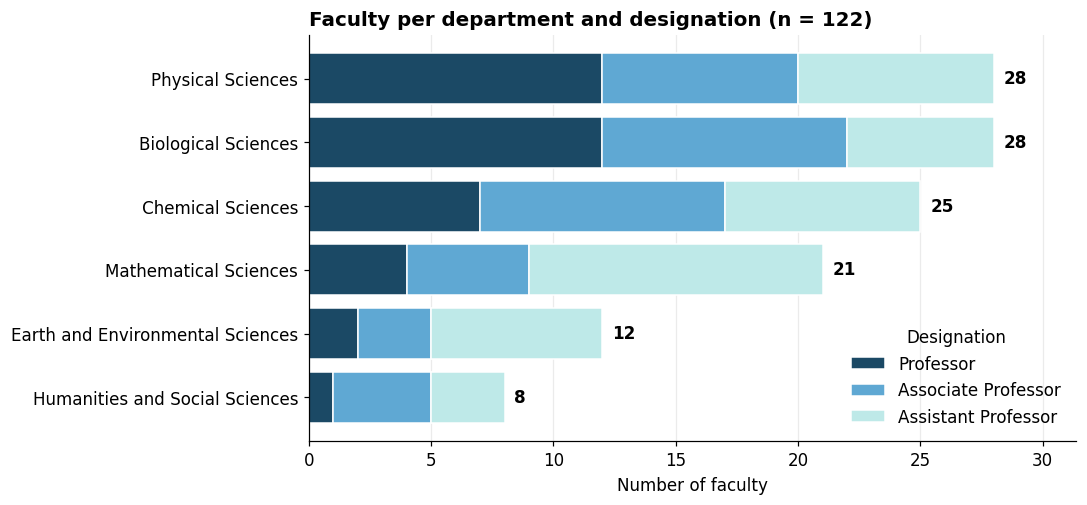

saved: /content/reports/figures/01_department_distribution.png
designation                       Professor  Associate Professor  Assistant Professor  Total  % of all faculty
department_name                                                                                               
Biological Sciences                      12                   10                    6     28              23.0
Physical Sciences                        12                    8                    8     28              23.0
Chemical Sciences                         7                   10                    8     25              20.5
Mathematical Sciences                     4                    5                   12     21              17.2
Earth and Environmental Sciences          2                    3                    7     12               9.8
Humanities and Social Sciences            1                    4                    3      8               6.6


In [ ]:
# DAY 5 / CELL 4 -- GRAPH 1: faculty per department and designation
ORDER  = ["Professor", "Associate Professor", "Assistant Professor"]
SHADES = ["#1b4965", "#5fa8d3", "#bee9e8"]

counts = (pd.crosstab(df["department_name"], df["designation"])      # count faculty by department and designation
            .reindex(columns=ORDER, fill_value=0))                    # fix the column order
counts = counts.loc[counts.sum(axis=1).sort_values().index]           # sort departments by size

fig, ax = plt.subplots(figsize=(9, 4.8))
left = np.zeros(len(counts))
for designation, shade in zip(ORDER, SHADES):
    ax.barh(counts.index, counts[designation], left=left, color=shade, edgecolor="white", label=designation)
    left += counts[designation].to_numpy()
for y, total in enumerate(left):                                      # write the total at the end of each bar
    ax.text(total + 0.4, y, f"{int(total)}", va="center", fontweight="bold")
ax.set_xlabel("Number of faculty")
ax.set_title(f"Faculty per department and designation (n = {len(df)})", loc="left")
ax.set_xlim(0, left.max() * 1.12)
ax.grid(axis="y", visible=False)
ax.legend(title="Designation", loc="lower right", frameon=False)
save_fig(fig, "01_department_distribution")

summary = counts.assign(Total=counts.sum(axis=1))
summary["% of all faculty"] = (summary["Total"] / len(df) * 100).round(1)
print(summary.sort_values("Total", ascending=False).to_string())

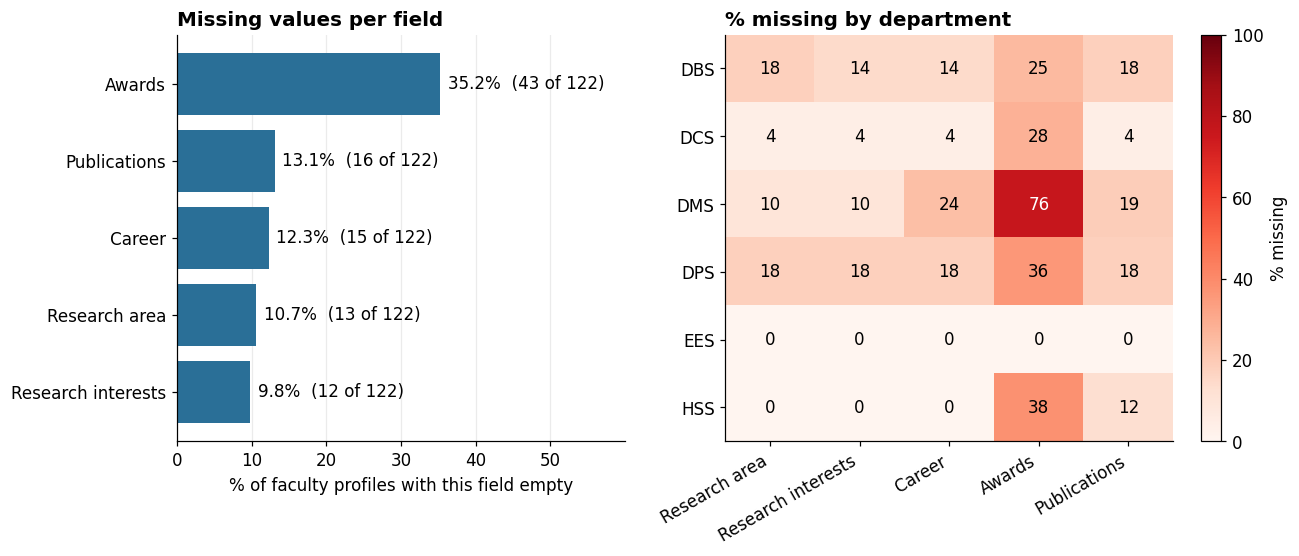

saved: /content/reports/figures/02_missing_values.png


In [ ]:
# DAY 5 / CELL 5 -- GRAPH 2: show missing information
TEXT_COLS = ["research_area", "research_interests", "career_text", "awards_text", "publications_text"]
NICE      = ["Research area", "Research interests", "Career", "Awards", "Publications"]

# find empty cells
blank = df[TEXT_COLS].apply(lambda col: col.fillna("").str.strip().eq(""))
pct   = blank.mean() * 100                       #missing data per column
n_miss = blank.sum()
order = list(pct.sort_values().index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})

# missing data per column
ax1.barh([NICE[TEXT_COLS.index(c)] for c in order], pct[order], color=BLUE)
for y, c in enumerate(order):
    ax1.text(pct[c] + 1, y, f"{pct[c]:.1f}%  ({n_miss[c]} of {len(df)})", va="center")
ax1.set_xlim(0, max(10, pct.max() * 1.7))
ax1.set_xlabel("% of faculty profiles with this field empty")
ax1.set_title("Missing values per field", loc="left")
ax1.grid(axis="y", visible=False)

# missing data by departmennt
by_dept = blank.groupby(df["department_code"]).mean() * 100
im = ax2.imshow(by_dept.to_numpy(), cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax2.set_xticks(range(len(TEXT_COLS)), labels=NICE, rotation=30, ha="right")
ax2.set_yticks(range(len(by_dept)), labels=list(by_dept.index))
for i in range(by_dept.shape[0]):
    for j in range(by_dept.shape[1]):
        v = by_dept.iat[i, j]
        ax2.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 55 else "black")
ax2.grid(False)
ax2.set_title("% missing by department", loc="left")
fig.colorbar(im, ax=ax2, label="% missing")
save_fig(fig, "02_missing_values")

Top 40 words (word, number of profiles) -- look for boring words to add to DOMAIN_STOP:
[('systems', 27), ('molecular', 25), ('theory', 20), ('biology', 20), ('physics', 19), ('chemistry', 19), ('understand', 18), ('quantum', 18), ('dynamics', 17), ('computational', 16), ('processes', 16), ('experimental', 15), ('interactions', 14), ('energy', 13), ('organic', 13), ('molecules', 13), ('matter', 12), ('properties', 12), ('model', 12), ('theoretical', 12), ('functional', 12), ('potential', 12), ('mechanisms', 12), ('problems', 12), ('materials', 12), ('information', 12), ('models', 12), ('biological', 11), ('cell', 11), ('synthetic', 11), ('mechanics', 10), ('developing', 10), ('novel', 10), ('genetics', 10), ('lie', 9), ('pathways', 9), ('groups', 9), ('transfer', 9), ('metal', 9), ('cellular', 9)]


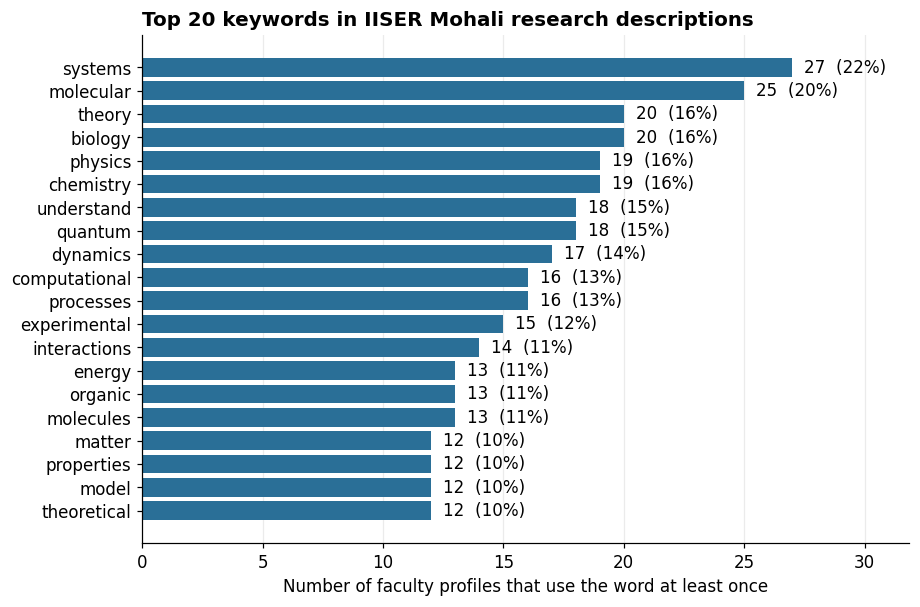

saved: /content/reports/figures/03_keyword_frequency.png

Top 8 keywords inside each department:
  DBS: biology, molecular, mechanisms, genetics, cellular, pathways, cell, host
  DCS: chemistry, organic, materials, systems, molecules, synthetic, synthesis, energy
  DMS: theory, groups, algebra, lie, algebraic, local, finite, geometry
  DPS: physics, quantum, matter, systems, mechanics, statistical, dynamics, information
  EES: processes, natural, impact, environmental, systems, sources, contribute, geochemistry
  HSS: history, social, literature, literary, urban, political, charles, apart


In [ ]:
# DAY 5 / CELL 6 -- find words which appear most often
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# remove common words that do not describe research
DOMAIN_STOP = {
    "research", "interests", "interest", "interested", "work", "working", "works", "study", "studies",
    "studying", "group", "including", "include", "includes", "currently", "also", "use", "using", "used",
    "based", "new", "understanding", "different", "various", "focus", "focuses", "focused", "area", "areas",
    "aspects", "particular", "particularly", "recent", "recently", "well", "mainly", "lab", "laboratory",
    "phd", "year", "years", "topics", "related", "field", "fields", "broad",
}
DOMAIN_STOP |= {"role", "approach", "approaches", "explore", "explores", "exploring", "themes", "techniques",
                 "involves", "involved", "key", "important", "aim", "aims", "investigate", "investigates",
                 "tools", "methods", "applications", "development"}
STOP = set(ENGLISH_STOP_WORDS) | DOMAIN_STOP

def tokenize(text):
    """Lower-case the text, keep word-like pieces (letters and hyphens), drop stop words."""
    words = re.findall(r"[a-z][a-z\-]+", text.lower())
    return [w for w in words if w not in STOP]

def doc_freq(texts):
    """For each word: in how many profiles does it appear? (set() = count a word once per person)"""
    counter = Counter()
    for t in texts:
        counter.update(set(tokenize(t)))
    return counter

texts  = df["profile_text"].fillna("")
counts = doc_freq(texts)

print("Top 40 words (word, number of profiles) -- look for boring words to add to DOMAIN_STOP:")
print(counts.most_common(40))

top = counts.most_common(20)[::-1]
words, vals = zip(*top)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(words, vals, color=BLUE)
for y, v in enumerate(vals):
    ax.text(v + 0.5, y, f"{v}  ({v / len(texts) * 100:.0f}%)", va="center")
ax.set_xlim(0, max(vals) * 1.18)
ax.set_xlabel("Number of faculty profiles that use the word at least once")
ax.set_title("Top 20 keywords in IISER Mohali research descriptions", loc="left")
ax.grid(axis="y", visible=False)
save_fig(fig, "03_keyword_frequency")

print("\nTop 8 keywords inside each department:")
for code, group in df.groupby("department_code"):
    top8 = [w for w, _ in doc_freq(group["profile_text"].fillna("")).most_common(8)]
    print(f"  {code}: {', '.join(top8)}")

In [ ]:
# DAY 5 / CELL 7 -- LOOK at the raw career text before trying to extract PhD institutes
has_career = df["career_text"].fillna("").str.strip() != ""
print("Faculty with career_text:", int(has_career.sum()), "of", len(df))
print("\n8 random examples (repr() shows hidden characters such as \\n):\n")
for text in df.loc[has_career, "career_text"].sample(8, random_state=42):
    print(repr(text[:220]))
    print()

Faculty with career_text: 107 of 122

8 random examples (repr() shows hidden characters such as \n):

'Since 2020 : Professor, IISER Mohali | 2013 - 2020 : Associate Professor, IISER Mohali | 2008 - 2013 : Assistant Professor, IISER Mohali | 2005 - 2008 : Postdoctoral Research Associate, The Scripps Research Institute, La'

'Since 2021 : Book Forum Editor for the Sage journal Dialogues in Human Geography. | Since 2019 : Editorial Board member for Elsevier journal Geoforum. | Since 2019 : Taylor and Francis journal Geopolitics | Advisory Boar'

'2020 - 2025 : Postdoctoral Fellow, University of California, San Diego, USA. | 2014 - 2019 : Ph.D. (Structural Biology), CSIR-Institute of Microbial Technology, Chandigarh, India. | 2011 - 2013 : M.Sc. (Human Genomics), '

'2024 : Affiliate, Madras Institute of Development Studies (MIDS), Chennai | 2023 : Fellow, International Centre for Ethnic Studies (ICES), Colombo | 2013 - 2020 : Assistant Professor in History, Department of Humanities '

'2

In [ ]:
# DAY 5 / CELL 8 extract phd institutions from career
PHD_START    = re.compile(r"^\s*\(?\s*(?:Ph\.?\s?D\.?|D\.?\s?Phil\.?|Doctorate|Doctor of Philosophy)", re.I)  # match phd entries
PAREN_PHD    = re.compile(r"\(\s*Ph\.?\s?D\.?[^)]*?\bby\s+([^)]+)\)", re.I)
NOT_A_DEGREE = re.compile(r"examiner|supervis|guid|committee|viva|advis|mentor|referee|reviewer", re.I)
TIER1 = re.compile(r"\b(?:Univ\w*|Institut\w*|Association|IIT|IISc|IISER|TIFR|NCBS|IOP|ETH)", re.I)   # match university names
TIER2 = re.compile(r"\b(?:College|School|Academy|Laborator\w*|Cent(?:re|er)|Polytechnic)", re.I)      # match department names
BARE  = re.compile(r"(?:Indian Institute of Technology|IIT|Indian Institute of Science Education (?:and|&) Research|IISER)", re.I)

# standardise institute names.
CANONICAL = [
    (r"\bIISc\b|Indian Institute of Science\b(?!\s+Education)",                "IISc"),
    (r"\bTIFR\b|Tata Institute of Fundamental Research",                       "TIFR"),
    (r"\bNCBS\b|National Centre for Biological Sciences",                      "NCBS"),
    (r"Harish[- ]Chandra Research Institute",                                  "Harish-Chandra Research Institute"),
    (r"Raman Research Institute",                                              "Raman Research Institute"),
    (r"Savitribai Phule Pune University|University of Pune|Pune University",   "Savitribai Phule Pune University"),
    (r"Institute of Microbial Technology|IMTECH",                              "CSIR-IMTECH"),
    (r"\bIOP\b.*Bhubaneswar|Institute of Physics,? Bhubaneswar",               "Institute of Physics Bhubaneswar"),
]
INSTITUTE_FIXES = {
    "Aryabhatta Research Institute of observational sciencES": "Aryabhatta Research Institute of Observational Sciences",
}
MANUAL_PHD = {
    "Baerbel Sinha":      "Max Planck Institute for Chemistry",
    "S. Arulananda babu": "CSMCRI (Bhavnagar University)",

}

def phd_entry(career_text):
    """Return the one career entry that describes the person's PhD degree, or None."""
    if not isinstance(career_text, str):
        return None
    entries = [e.strip() for e in career_text.split("|")]            # one career step at a time
    for entry in entries:                                             # 1st choice: an entry that STARTS with Ph.D.
        desc = re.split(r"\s*:\s*", entry, maxsplit=1)[-1]            # drop the '2014 - 2019 :' part
        m = PHD_START.match(desc)
        if m and not NOT_A_DEGREE.search(desc[m.end(): m.end() + 40]):
            return desc
    for entry in entries:                                             # 2nd choice: '(PhD awarded by X)' hidden inside another entry
        if PAREN_PHD.search(entry):
            return entry
    return None

def institute_from_entry(desc):
    """From 'Ph.D. (Subject), Institute, City, Country' pick the institute part."""
    if not PHD_START.match(desc):
        return PAREN_PHD.search(desc).group(1).strip(" .")
    rest = desc[PHD_START.match(desc).end():]
    rest = re.sub(r"\([^)]*(?:\)|$)", " ", rest)
    rest = re.sub(r"\b(?:19|20)\d{2}\b", " ", rest)
    rest = re.sub(r"\b(?:degree|awarded|conferred|received|obtained|completed)\b", " ", rest, flags=re.I)
    by = re.search(r"\b(?:by|from)\s+(.*)$", rest, flags=re.I)
    if by:
        rest = by.group(1)
    rest = re.sub(r"^\s*(?:at|in)\s+", "", rest, flags=re.I)
    rest = re.sub(r"\s+in\s*$", "", rest, flags=re.I)
    parts = [re.sub(r"^(?:and|&)\s+", "", p.strip(" .:-–()"), flags=re.I) for p in rest.split(",")]
    parts = [p for p in parts if p]
    for pattern in (TIER1, TIER2):
        for i, part in enumerate(parts):
            if pattern.search(part):
                if BARE.fullmatch(part) and i + 1 < len(parts):
                    part = part + " " + parts[i + 1]
                return part
    return None

def normalise_institute(name):
    name = re.sub(r"\s+", " ", name).strip(" ,.-/")
    for pattern, short in CANONICAL:
        if re.search(pattern, name, flags=re.I):
            return short
    name = re.sub(r"Indian Institute of Science Education (?:and|&) Research,?\s*", "IISER ", name, flags=re.I)
    name = re.sub(r"Indian Institute of Technology,?\s*", "IIT ", name, flags=re.I)
    name = re.sub(r"^the\s+", "", name, flags=re.I)
    return INSTITUTE_FIXES.get(name, name)

df["phd_entry"]     = df["career_text"].apply(phd_entry)
df["phd_institute"] = df["phd_entry"].apply(lambda d: institute_from_entry(d) if isinstance(d, str) else None)
df["phd_institute"] = df["phd_institute"].apply(lambda s: normalise_institute(s) if isinstance(s, str) else None)
df.loc[df["phd_institute"].fillna("").str.len() > 70, "phd_institute"] = None
for person, institute in MANUAL_PHD.items():
    df.loc[df["name"] == person, "phd_institute"] = institute

n_found = int(df["phd_institute"].notna().sum())
print(f"PhD institute available for {n_found} of {len(df)} faculty.\n")

print("CHECK 1 -- 15 random successes: the PhD entry we read  ->  our answer")
for _, r in df[df["phd_institute"].notna()].sample(min(15, n_found), random_state=1).iterrows():
    entry = r["phd_entry"] if isinstance(r["phd_entry"], str) else "(manual override)"
    print(f"  {entry[:75]!r:80} -> {r['phd_institute']}")

def phd_mentions(text):
    """Career entries that talk about the person's own PhD (a 'Postdoctoral' entry does NOT count)."""
    out = []
    for e in text.split("|"):
        has_phd    = re.search(r"Ph\.?\s?D", e, flags=re.I)
        has_doctor = re.search(r"\bDoctor(?:ate|al)?\b", e, flags=re.I) and not re.search(r"Post[\s-]*doc", e, flags=re.I)
        if has_phd or has_doctor:
            out.append(e.strip())
    return out

failed = df[df["career_text"].fillna("").apply(lambda t: len(phd_mentions(t)) > 0) & df["phd_institute"].isna()]
print(f"\nCHECK 2 -- a PhD entry exists but no institute was read: {len(failed)} people")
for _, r in failed.iterrows():
    print(f"  {r['name']}:")
    for e in phd_mentions(r["career_text"])[:2]:
        print(f"      {e[:120]!r}")

print("\nCHECK 3 -- every distinct institute (most common first; look for the same place spelled two ways):")
print(df["phd_institute"].value_counts().sort_index().sort_values(ascending=False, kind="stable").to_string())

def show(text):
    """Print name | PhD entry we read | our answer, for everyone whose career text or institute contains `text`."""
    hit = df[df["career_text"].fillna("").str.contains(text, case=False, regex=False)
             | df["phd_institute"].fillna("").str.contains(text, case=False, regex=False)]
    for _, r in hit.iterrows():
        entry = r["phd_entry"] if isinstance(r["phd_entry"], str) else "(none)"
        print(f"{r['name']:28} | {entry[:90]!r} -> {r['phd_institute']}")

PhD institute available for 93 of 122 faculty.

CHECK 1 -- 15 random successes: the PhD entry we read  ->  our answer
  'Ph.D., Indian Institute of Science, Bangalore, India (Advisor: Prof. A. Sri'    -> IISc
  'Ph.D. Organic Geochemistry, IIT Bombay'                                         -> IIT Bombay
  'PhD in Physics, Jawaharlal Nehru University'                                    -> Jawaharlal Nehru University
  'PhD Scholar, Biology Department, IISER Pune, Maharashtra, India'                -> IISER Pune
  'PhD, IISc Bangalore'                                                            -> IISc
  'PhD, Indian Institute of Technology Kharagpur'                                  -> IIT Kharagpur
  'PhD, National Centre for Biological Sciences (NCBS), Tata Institute of Fund'    -> TIFR
  'Ph.D. in Atmospheric Sciences, Indian Institute of Tropical Meteorology (II'    -> Indian Institute of Tropical Meteorology
  'PhD, Technical University of Munich, Germany'                          

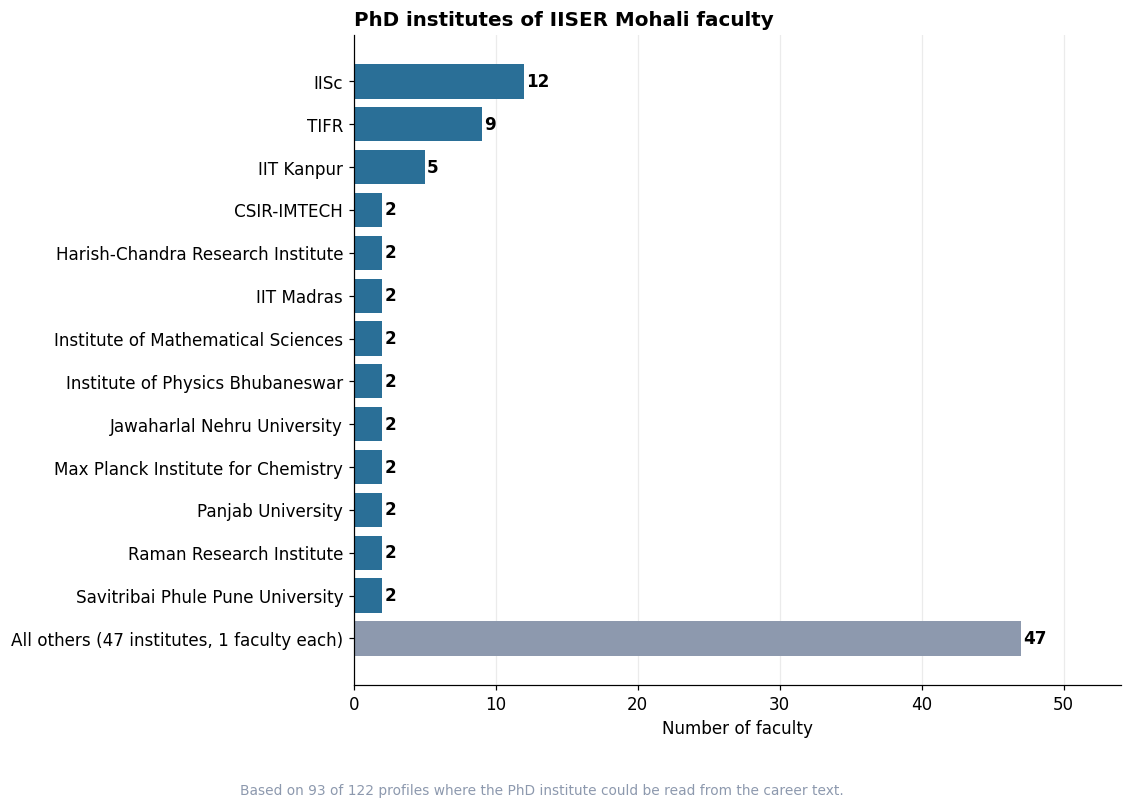

saved: /content/reports/figures/04_phd_institutes.png


In [ ]:
# DAY 5 / CELL 9 (REPLACEMENT) -- faculty phd institutes
n_found = int(df["phd_institute"].notna().sum())
inst    = df["phd_institute"].value_counts()
inst    = inst.sort_index().sort_values(ascending=False, kind="stable")    # sort by faculty count
shown   = inst[inst >= 2].head(15)                                          # institutes with multiple faculty
rest    = inst.drop(shown.index)                                            # 1 faculty member

bars    = shown
colours = [BLUE] * len(shown)
if len(rest):
    label   = f"All others ({len(rest)} institutes, 1 faculty each)" if (rest == 1).all() else f"All others ({len(rest)} institutes)"
    bars    = pd.concat([shown, pd.Series({label: int(rest.sum())})])
    colours = colours + [GREY]
bars, colours = bars.iloc[::-1], colours[::-1]                              # biggest bar at the top

fig, ax = plt.subplots(figsize=(9, 0.42 * len(bars) + 1.8))
ax.barh(bars.index, bars.values, color=colours)
for y, v in enumerate(bars.values):
    ax.text(v + 0.15, y, str(int(v)), va="center", fontweight="bold")
ax.set_xlim(0, bars.max() * 1.15)
ax.set_xlabel("Number of faculty")
ax.set_title("PhD institutes of IISER Mohali faculty", loc="left")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, f"Based on {n_found} of {len(df)} profiles where the PhD institute could be read from the career text.",
         fontsize=9, color=GREY)
save_fig(fig, "04_phd_institutes")

count    110.0
mean     107.3
std       74.9
min        9.0
25%       47.2
50%       92.5
75%      168.2
max      360.0

Unusually long profiles (> 350 words):
                 name department_code  profile_text_words
Sugumar Venkataramani             DCS                 360

Profiles flagged very_short on Day 3: 8


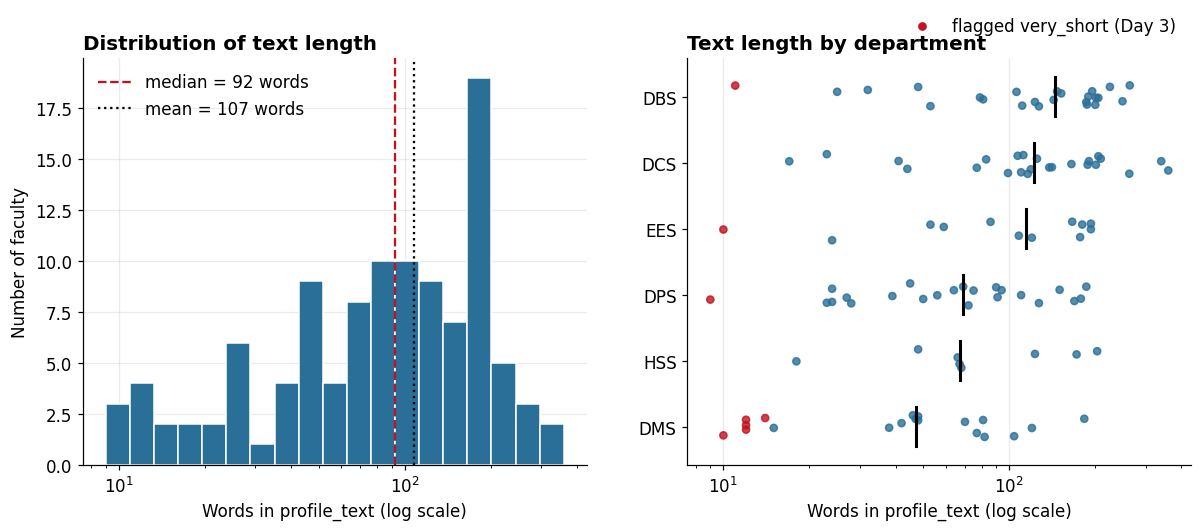

saved: /content/reports/figures/05_text_length.png


In [ ]:
# DAY 5 / CELL 10 -- analyse profile text length
plot_df = df[df["profile_text_words"] > 0]                 # log scale cannot show 0
words   = plot_df["profile_text_words"]
print(words.describe().round(1).to_string())

q1, q3 = words.quantile([0.25, 0.75])
upper  = q3 + 1.5 * (q3 - q1)                              # identify unusually long profiles
print(f"\nUnusually long profiles (> {upper:.0f} words):")
print(plot_df.loc[words > upper, ["name", "department_code", "profile_text_words"]]
             .sort_values("profile_text_words", ascending=False).to_string(index=False))
print("\nProfiles flagged very_short on Day 3:", int((df["text_quality"] == "very_short").sum()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# show test length distribution
bins = np.logspace(np.log10(words.min()), np.log10(words.max()), 20)
ax1.hist(words, bins=bins, color=BLUE, edgecolor="white")
ax1.set_xscale("log")
ax1.axvline(words.median(), color=RED, ls="--", label=f"median = {words.median():.0f} words")
ax1.axvline(words.mean(),   color="black", ls=":", label=f"mean = {words.mean():.0f} words")
ax1.set_xlabel("Words in profile_text (log scale)")
ax1.set_ylabel("Number of faculty")
ax1.set_title("Distribution of text length", loc="left")
ax1.legend(frameon=False)

# compare text lengths across departments
order = list(plot_df.groupby("department_code")["profile_text_words"].median().sort_values().index)
rng   = np.random.default_rng(42)                           # keep results consistent
for y, code in enumerate(order):
    sub    = plot_df[plot_df["department_code"] == code]
    jitter = rng.uniform(-0.18, 0.18, len(sub))             # avoid overlapping dots
    colour = np.where(sub["text_quality"] == "very_short", RED, BLUE)
    ax2.scatter(sub["profile_text_words"], y + jitter, c=colour, s=22, alpha=0.8)
    ax2.plot([sub["profile_text_words"].median()] * 2, [y - 0.3, y + 0.3], color="black", lw=2)
ax2.scatter([], [], c=RED, s=22, label="flagged very_short (Day 3)")
ax2.set_xscale("log")
ax2.set_yticks(range(len(order)), labels=order)
ax2.set_xlabel("Words in profile_text (log scale)")
ax2.set_title("Text length by department", loc="left")
ax2.grid(axis="y", visible=False)
ax2.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.02))
save_fig(fig, "05_text_length")

In [ ]:
# DAY 5 / CELL 10B -- check profiles with shortest text
for _, r in df.nsmallest(12, "profile_text_words").iterrows():
    print(f"{r['name']} ({r['department_code']}) -- {r['profile_text_words']} words, text_source = {r['text_source']}, text_quality = {r['text_quality']}")
    print("    TEXT:", r["profile_text"])

Alok Maharana (DMS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Ananth Venkatesan (DPS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Dipanjan Chakraborty (DPS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Goutam Sheet (DPS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
K. P. Yogendran (DPS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Kuljeet Sandhu (DBS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Lolitika Mandal (DBS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Purnananda Guptasarma (DBS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Sanjay Mandal (DCS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Satyajit Jena (DPS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Sudip Mandal (DBS) -- 0 words, text_source = none, text_quality = none
    TEXT: None
Yashonidhi Pandey (DM

In [ ]:
# DAY 5 / CELL 11 -- keep a copy of every figure on Google Drive
if DRIVE.exists():
    dest = DRIVE / "reports_figures"
    dest.mkdir(parents=True, exist_ok=True)
    for f in sorted(FIG_DIR.glob("*.png")):
        shutil.copy(f, dest / f.name)
        print("copied:", f.name)
    print("Figures are on Drive in:", dest)
else:
    print("Drive is not mounted -- run drive.mount('/content/drive') first.")

copied: 01_department_distribution.png
copied: 02_missing_values.png
copied: 03_keyword_frequency.png
copied: 04_phd_institutes.png
copied: 05_text_length.png
Figures are on Drive in: /content/drive/MyDrive/faculty_profile_explorer/reports_figures


In [ ]:
# DAY 6 / CELL 1 -- calculate TF-IDF manually then compare with scikit-learn
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

toy   = ["quantum physics of matter",
         "quantum chemistry of molecules",
         "organic chemistry of molecules"]

# STEP 1 -- count word frequencies
cv     = CountVectorizer(stop_words=["of"])
counts = cv.fit_transform(toy).toarray()
terms  = cv.get_feature_names_out()
print("TERM COUNTS (tf)"); print(pd.DataFrame(counts, index=["d1", "d2", "d3"], columns=terms))

# STEP 2 -- calculate idf
n    = len(toy)
df_t = (counts > 0).sum(axis=0)
idf  = np.log((1 + n) / (1 + df_t)) + 1
print("\nIDF"); print(pd.DataFrame({"df": df_t, "idf": idf.round(4)}, index=terms).T)

# STEP 3 -- calculate and normalise tf-idf
raw    = counts * idf                                   # tf x idf
manual = raw / np.linalg.norm(raw, axis=1, keepdims=True)
print("\nTF-IDF (by hand)"); print(pd.DataFrame(manual, index=["d1", "d2", "d3"], columns=terms).round(3))

# STEP 4 -- compare with sklearn results
sk = TfidfVectorizer(stop_words=["of"]).fit_transform(toy).toarray()
print("\nBy-hand result equals scikit-learn's result:", np.allclose(manual, sk))

TERM COUNTS (tf)
    chemistry  matter  molecules  organic  physics  quantum
d1          0       1          0        0        1        1
d2          1       0          1        0        0        1
d3          1       0          1        1        0        0

IDF
     chemistry  matter  molecules  organic  physics  quantum
df      2.0000  1.0000     2.0000   1.0000   1.0000   2.0000
idf     1.2877  1.6931     1.2877   1.6931   1.6931   1.2877

TF-IDF (by hand)
    chemistry  matter  molecules  organic  physics  quantum
d1      0.000   0.623      0.000    0.000    0.623    0.474
d2      0.577   0.000      0.577    0.000    0.000    0.577
d3      0.518   0.000      0.518    0.681    0.000    0.000

By-hand result equals scikit-learn's result: True


In [ ]:
# DAY 6 --  REBUILD of every Day 6 file
import re, shutil, sqlite3, joblib
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

# set pathsand look at what already exists
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    pass
ROOT      = Path("/content") if Path("/content").exists() else Path.cwd()
DRIVE     = Path("/content/drive/MyDrive/faculty_profile_explorer")
FEAT_DIR  = ROOT / "data" / "features"; FEAT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models";            MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("Drive mounted:", DRIVE.exists())
for folder in (FEAT_DIR, DRIVE / "data_features"):
    print(" ", folder, "->", sorted(p.name for p in folder.glob("*")) if folder.exists() else "(folder not found)")

# - load the profiles from the database
local_dbs = sorted(ROOT.glob("data/**/faculty.db"))
if local_dbs:
    DB_PATH = local_dbs[0]
else:                                                     # restore database from drive
    DB_PATH = ROOT / "data" / "db" / "faculty.db"
    DB_PATH.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE / "data_db" / "faculty.db", DB_PATH)
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")

def load_profiles():
    return pd.read_sql_query(
        "SELECT faculty_id, name, department_code, text_quality, profile_text FROM faculty ORDER BY faculty_id", conn)

def count_empty(frame):
    return int(frame["profile_text"].fillna("").str.strip().eq("").sum())

df = load_profiles()
print("\nUsing database:", DB_PATH, "| empty profile_text:", count_empty(df))
if count_empty(df):
    print("The database is the OLD version. Repairing it from faculty_cleaned.csv ...")
    fresh = None
    for candidate in (ROOT / "data" / "processed" / "faculty_cleaned.csv", DRIVE / "data_processed" / "faculty_cleaned.csv"):
        if candidate.exists():
            frame = pd.read_csv(candidate)
            if not (frame["text_quality"] == "none").any():
                fresh, csv_path = frame, candidate
                break
    if fresh is None:
        raise RuntimeError("No good faculty_cleaned.csv found. Re-run Day 3 Cells 2-5, then run this cell again.")
    if set(fresh["faculty_id"]) != {r[0] for r in conn.execute("SELECT faculty_id FROM faculty")}:
        raise RuntimeError("faculty_id values differ between the CSV and the database -> re-run the Day 4 build cell.")
    db_cols = [r[1] for r in conn.execute("PRAGMA table_info(faculty)")]
    cols    = [c for c in db_cols if c in fresh.columns and c not in {"faculty_id", "reviewed", "review_note"}]
    def to_python(v):
        if pd.isna(v):
            return None
        return v.item() if hasattr(v, "item") else v
    sql  = f"UPDATE faculty SET {', '.join(c + ' = ?' for c in cols)} WHERE faculty_id = ?"
    rows = [[to_python(r[c]) for c in cols] + [to_python(r["faculty_id"])] for _, r in fresh.iterrows()]
    with conn:
        conn.executemany(sql, rows)
    if DRIVE.exists():
        (DRIVE / "data_db").mkdir(exist_ok=True)
        shutil.copy(DB_PATH, DRIVE / "data_db" / "faculty.db")
    df = load_profiles()
    print(f"  repaired {len(rows)} rows from {csv_path.name}; empty profile_text now: {count_empty(df)}")
if count_empty(df):
    raise RuntimeError("Some profiles are still empty. Stop here and send me the lines printed above.")
print(df["text_quality"].value_counts().to_string())

# set stop words and tokenizer
DOMAIN_STOP = {
    "research", "interests", "interest", "interested", "work", "working", "works", "study", "studies", "studying",
    "group", "including", "include", "includes", "currently", "also", "use", "using", "used", "based", "new",
    "understanding", "different", "various", "focus", "focuses", "focused", "area", "areas", "aspects",
    "particular", "particularly", "recent", "recently", "well", "mainly", "lab", "laboratory", "phd", "year",
    "years", "topics", "related", "field", "fields", "broad", "role", "approach", "approaches", "explore",
    "explores", "exploring", "themes", "techniques", "involves", "involved", "key", "important", "aim", "aims",
    "investigate", "investigates", "tools", "methods", "applications", "development",
    "understand", "like", "current", "novel", "developing", "apart", "contribute",
    "certain", "addresses", "influences", "long", "term",
}
KEEP_WORDS    = {"system", "thin", "thick", "fire", "top", "bottom"}
STOP          = sorted((set(ENGLISH_STOP_WORDS) - KEEP_WORDS) | DOMAIN_STOP)
TOKEN_PATTERN = r"[a-z]{2,}"

#  create two TF-IDF matrices
MAX_DF = 0.5
def make_vectorizer(min_df):
    return TfidfVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN, stop_words=STOP,
                           min_df=min_df, max_df=MAX_DF, sublinear_tf=True, norm="l2")

texts       = df["profile_text"].fillna("")
vec_search  = make_vectorizer(min_df=1)
vec_cluster = make_vectorizer(min_df=2)
X_search    = vec_search.fit_transform(texts)
X_cluster   = vec_cluster.fit_transform(texts)

def report(name, vec, M):
    terms = vec.get_feature_names_out()
    n_docs, n_terms = M.shape
    wpr      = np.diff(M.indptr)
    row_len  = np.sqrt(np.asarray(M.multiply(M).sum(axis=1)).ravel())
    doc_freq = np.asarray((M > 0).sum(axis=0)).ravel()
    print(f"--- {name} ---")
    print("shape (faculty, words):", M.shape, "| sparsity: %.2f%%" % (100 * (1 - M.nnz / (n_docs * n_terms))))
    print("words used by exactly 1 profile:", int((doc_freq == 1).sum()), "of", n_terms)
    print("words kept per profile: min", int(wpr.min()), "| median", int(np.median(wpr)), "| max", int(wpr.max()))
    print("profiles with NO word left:", int((wpr == 0).sum()), "| every other row has length 1:", bool(np.allclose(row_len[wpr > 0], 1.0)))
    for i in np.where(wpr < 5)[0]:
        print(f"   few words: {df.loc[i, 'name']} ({df.loc[i, 'department_code']}) -> {int(wpr[i])} word(s) | text: {texts.iloc[i][:70]!r}")
    return pd.DataFrame({"term": terms, "doc_freq": doc_freq, "idf": vec.idf_})

print()
table_search  = report("SEARCH matrix (min_df=1)", vec_search, X_search)
table_cluster = report("CLUSTER matrix (min_df=2)", vec_cluster, X_cluster)

def top_terms(M, vec, i, k=8):
    terms = vec.get_feature_names_out(); row = M.getrow(i); order = np.argsort(row.data)[::-1][:k]
    return [(terms[row.indices[j]], round(float(row.data[j]), 3)) for j in order]
print("\nSanity check -- top words of the first person in each department:")
for i in df.groupby("department_code").head(1).index:
    print(f"  {df.loc[i, 'name']} ({df.loc[i, 'department_code']})")
    print("     search :", top_terms(X_search, vec_search, i))
    print("     cluster:", top_terms(X_cluster, vec_cluster, i))

#  save everything
sparse.save_npz(FEAT_DIR / "tfidf_search_matrix.npz",  X_search)
sparse.save_npz(FEAT_DIR / "tfidf_cluster_matrix.npz", X_cluster)
table_search.to_csv(FEAT_DIR / "tfidf_search_feature_names.csv", index=False)
table_cluster.to_csv(FEAT_DIR / "tfidf_cluster_feature_names.csv", index=False)
df[["faculty_id", "name", "department_code"]].to_csv(FEAT_DIR / "tfidf_row_order.csv", index=False)
joblib.dump(vec_search,  MODEL_DIR / "tfidf_vectorizer_search.joblib")
joblib.dump(vec_cluster, MODEL_DIR / "tfidf_vectorizer_cluster.joblib")

if DRIVE.exists():
    for folder, files in [("data_features", FEAT_DIR.glob("*")), ("models", MODEL_DIR.glob("*"))]:
        (DRIVE / folder).mkdir(exist_ok=True)
        for f in files:
            shutil.copy(f, DRIVE / folder / f.name)

NEEDED = ["tfidf_search_matrix.npz", "tfidf_cluster_matrix.npz", "tfidf_cluster_feature_names.csv", "tfidf_row_order.csv"]
print("\nFINAL CHECK")
print("  files in data/features:", all((FEAT_DIR / n).exists() for n in NEEDED))
print("  files on Drive        :", all((DRIVE / "data_features" / n).exists() for n in NEEDED) if DRIVE.exists() else "Drive not mounted")
back = sparse.load_npz(FEAT_DIR / "tfidf_cluster_matrix.npz")
print("  cluster matrix reloads identical:", (back != X_cluster).nnz == 0, "| shape", back.shape)

Drive mounted: True
  /content/data/features -> []
  /content/drive/MyDrive/faculty_profile_explorer/data_features -> ['cluster_keywords.csv', 'faculty_clusters.csv', 'faculty_reduced.csv', 'faculty_reduced.npy', 'svd_explained_variance.csv', 'tfidf_cluster_feature_names.csv', 'tfidf_cluster_matrix.npz', 'tfidf_feature_names.csv', 'tfidf_matrix.npz', 'tfidf_row_order.csv', 'tfidf_search_feature_names.csv', 'tfidf_search_matrix.npz']

Using database: /content/data/db/faculty.db | empty profile_text: 12
The database is the OLD version. Repairing it from faculty_cleaned.csv ...
  repaired 122 rows from faculty_cleaned.csv; empty profile_text now: 0
text_quality
ok            113
very_short      9

--- SEARCH matrix (min_df=1) ---
shape (faculty, words): (122, 3291) | sparsity: 98.41%
words used by exactly 1 profile: 2149 of 3291
words kept per profile: min 2 | median 44 | max 321
profiles with NO word left: 0 | every other row has length 1: True
   few words: Lingaraj Sahu (DMS) -> 3 word

In [ ]:
# DAY 7 / CELL 1 -- load the Day 6 files and check them
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

ROOT     = Path("/content") if Path("/content").exists() else Path.cwd()
DRIVE    = Path("/content/drive/MyDrive/faculty_profile_explorer")
FEAT_DIR = ROOT / "data" / "features";   FEAT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models";             MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

NEEDED = ["tfidf_search_matrix.npz", "tfidf_cluster_matrix.npz", "tfidf_cluster_feature_names.csv", "tfidf_row_order.csv"]
for name in NEEDED:                                          # restore missing files
    if not (FEAT_DIR / name).exists() and (DRIVE / "data_features" / name).exists():
        shutil.copy(DRIVE / "data_features" / name, FEAT_DIR / name)
missing = [n for n in NEEDED if not (FEAT_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run the REVISED Day 6 Cells 2-6 first.")

X_search  = sparse.load_npz(FEAT_DIR / "tfidf_search_matrix.npz").tocsr()
X_cluster = sparse.load_npz(FEAT_DIR / "tfidf_cluster_matrix.npz").tocsr()
rows      = pd.read_csv(FEAT_DIR / "tfidf_row_order.csv")
terms     = pd.read_csv(FEAT_DIR / "tfidf_cluster_feature_names.csv")["term"].to_numpy()

def words_per_row(M):
    return np.diff(M.indptr)

def row_lengths(M):
    return np.sqrt(np.asarray(M.multiply(M).sum(axis=1)).ravel())

# check for errors
problems = []
if not (X_search.shape[0] == X_cluster.shape[0] == len(rows)):
    problems.append("the matrices and the row-order file have different numbers of rows")
if X_cluster.shape[1] != len(terms):
    problems.append("the feature-name file does not match the cluster matrix")
n_empty_search = int((words_per_row(X_search) == 0).sum())
if n_empty_search:
    problems.append(f"{n_empty_search} profiles have NO words even in the SEARCH matrix -> their text was empty "
                    "(old database). Re-run Day 5 Cell 1 (and Cell 2 if it says STOP), then Day 6 Cells 2-6.")
for name, M in [("search", X_search), ("cluster", X_cluster)]:
    nz = words_per_row(M) > 0
    if not np.allclose(row_lengths(M)[nz], 1.0):
        problems.append(f"{name} matrix: some non-empty rows do not have length 1")
if problems:
    raise RuntimeError("HEALTH GATE FAILED:\n - " + "\n - ".join(problems))

cluster_mask = words_per_row(X_cluster) > 0          # profiles with shared words
print("HEALTH GATE PASSED")
print("cluster matrix:", X_cluster.shape, "| search matrix:", X_search.shape)
print("profiles usable for clustering:", int(cluster_mask.sum()), "of", len(rows))
for i in np.where(~cluster_mask)[0]:
    print("   NOT usable (no word shared with any other profile):", rows.loc[i, "name"], f"({rows.loc[i, 'department_code']})")

HEALTH GATE PASSED
cluster matrix: (122, 1142) | search matrix: (122, 3291)
profiles usable for clustering: 122 of 122


In [ ]:
# DAY 7 / CELL 2 -- fit a Truncated SVD with many components and look at the explained variance
from sklearn.decomposition import TruncatedSVD

K_MAX = min(100, X_cluster.shape[1] - 1, X_cluster.shape[0] - 1)
svd_full = TruncatedSVD(n_components=K_MAX, algorithm="randomized", n_iter=7, random_state=42)
svd_full.fit(X_cluster)

ratio = svd_full.explained_variance_ratio_
cum   = np.cumsum(ratio)
print(f"Components fitted: {K_MAX}")
print("First 10 individual ratios:", np.round(ratio[:10], 4))
print(f"Total variance kept by all {K_MAX} components: {cum[-1]:.1%}\n")
for target in (0.50, 0.70, 0.80, 0.90):
    k = int(np.searchsorted(cum, target) + 1) if cum[-1] >= target else None
    print(f"  components needed for {target:.0%} of the variance:", k if k else f"not reached within {K_MAX}")

Components fitted: 100
First 10 individual ratios: [0.0074 0.03   0.0261 0.0229 0.0211 0.019  0.0169 0.0151 0.0146 0.0145]
Total variance kept by all 100 components: 92.0%

  components needed for 50% of the variance: 39
  components needed for 70% of the variance: 63
  components needed for 80% of the variance: 78
  components needed for 90% of the variance: 96


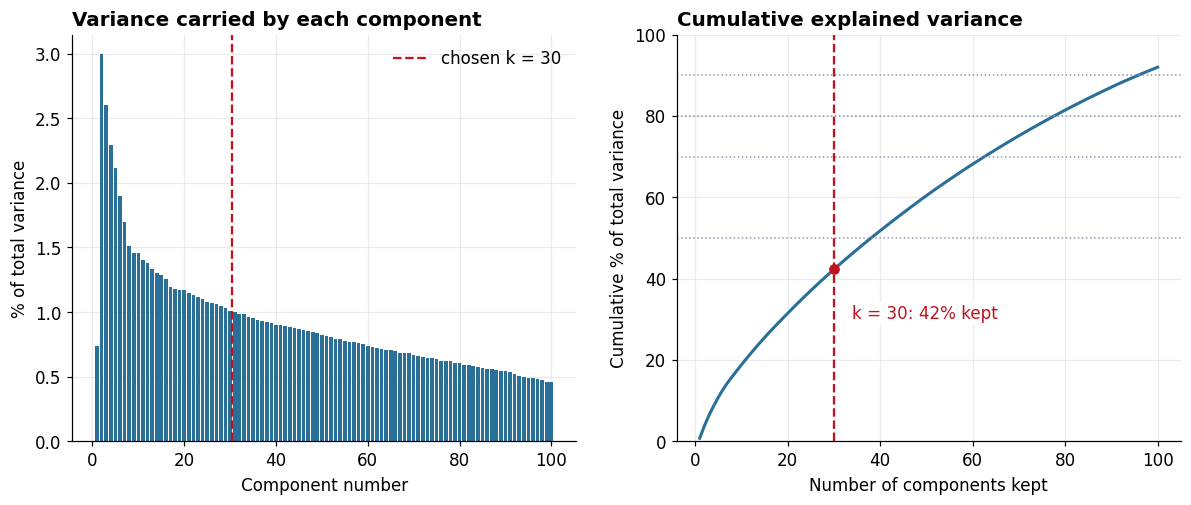

saved: /content/reports/figures/06_svd_explained_variance.png


In [ ]:
# DAY 7 / CELL 3 -- plot explained variance
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
BLUE, GREY, RED = "#2a6f97", "#8d99ae", "#c1121f"

N_COMPONENTS = 30
assert N_COMPONENTS <= K_MAX, f"N_COMPONENTS must be <= {K_MAX}"

x = np.arange(1, K_MAX + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.bar(x, ratio * 100, color=BLUE)
ax1.axvline(N_COMPONENTS + 0.5, color=RED, ls="--", label=f"chosen k = {N_COMPONENTS}")
ax1.set_xlabel("Component number"); ax1.set_ylabel("% of total variance")
ax1.set_title("Variance carried by each component", loc="left"); ax1.legend(frameon=False)

ax2.plot(x, cum * 100, color=BLUE, lw=2)
for target in (50, 70, 80, 90):
    ax2.axhline(target, color=GREY, ls=":", lw=1)
ax2.axvline(N_COMPONENTS, color=RED, ls="--")
ax2.plot([N_COMPONENTS], [cum[N_COMPONENTS - 1] * 100], "o", color=RED)
ax2.annotate(f"k = {N_COMPONENTS}: {cum[N_COMPONENTS - 1]:.0%} kept", (N_COMPONENTS, cum[N_COMPONENTS - 1] * 100),
             xytext=(N_COMPONENTS + 4, cum[N_COMPONENTS - 1] * 100 - 12), color=RED,
             bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax2.set_xlabel("Number of components kept"); ax2.set_ylabel("Cumulative % of total variance")
ax2.set_title("Cumulative explained variance", loc="left")
ax2.set_ylim(0, 100)

path = FIG_DIR / "06_svd_explained_variance.png"
fig.savefig(path); plt.show(); print("saved:", path)

In [ ]:
# DAY 7 / CELL 4 -- reduce features using SVD and normalise
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics.pairwise import cosine_similarity

lsa = make_pipeline(
    TruncatedSVD(n_components=N_COMPONENTS, algorithm="randomized", n_iter=7, random_state=42),
    Normalizer(copy=False),                                                                       # normalise profile lengths
)
X_reduced = lsa.fit_transform(X_cluster)
svd       = lsa.named_steps["truncatedsvd"]

print("Reduced matrix shape:", X_reduced.shape, "(was", X_cluster.shape, ")")
print(f"Variance kept by the {N_COMPONENTS} components: {svd.explained_variance_ratio_.sum():.1%}")
lens = np.linalg.norm(X_reduced, axis=1)
print("Row lengths equal 1 for every usable profile:", bool(np.allclose(lens[cluster_mask], 1.0)))

# compare similarities before and after reduction
pairs      = np.triu_indices(X_cluster.shape[0], k=1)
sim_before = cosine_similarity(X_cluster)[pairs]
sim_after  = cosine_similarity(X_reduced)[pairs]
print(f"Similarity before vs after reduction -> Pearson r = {np.corrcoef(sim_before, sim_after)[0, 1]:.3f}, "
      f"Spearman rho = {pd.Series(sim_before).corr(pd.Series(sim_after), method='spearman'):.3f}")
print("Component 1: all loadings share one sign:", bool((svd.components_[0] >= 0).all() or (svd.components_[0] <= 0).all()))

Reduced matrix shape: (122, 30) (was (122, 1142) )
Variance kept by the 30 components: 42.1%
Row lengths equal 1 for every usable profile: True
Similarity before vs after reduction -> Pearson r = 0.866, Spearman rho = 0.771
Component 1: all loadings share one sign: True


In [ ]:
# DAY 7 / CELL 5 -- show the top positive and negative words for each component
comp = svd.components_                       # each row contains word weights for one component
for c in range(6):
    order = np.argsort(comp[c])
    pos   = ", ".join(terms[order[::-1][:8]])
    neg   = ", ".join(terms[order[:8]])
    line  = f"Component {c + 1:>2} ({svd.explained_variance_ratio_[c]:.1%} of variance)  +: {pos}"
    if c > 0:
        line += f"\n{'':37}-: {neg}"
    print(line)

Component  1 (0.7% of variance)  +: quantum, physics, matter, systems, theory, dynamics, molecular, chemistry
Component  2 (3.0% of variance)  +: theory, groups, algebraic, geometry, algebra, representation, lie, topology
                                     -: biology, cell, molecular, host, genetics, cellular, mechanisms, chemistry
Component  3 (2.6% of variance)  +: physics, quantum, matter, soft, mechanics, condensed, statistical, optics
                                     -: biology, host, genetics, cell, cellular, algebraic, mechanisms, molecular
Component  4 (2.3% of variance)  +: chemistry, organic, synthesis, metal, synthetic, molecules, materials, catalysis
                                     -: physics, matter, soft, cell, biology, genetics, statistical, dynamics
Component  5 (2.1% of variance)  +: algebraic, geometry, varieties, topology, real, motivic, surfaces, commutative
                                     -: theory, groups, representation, lie, adic, representations

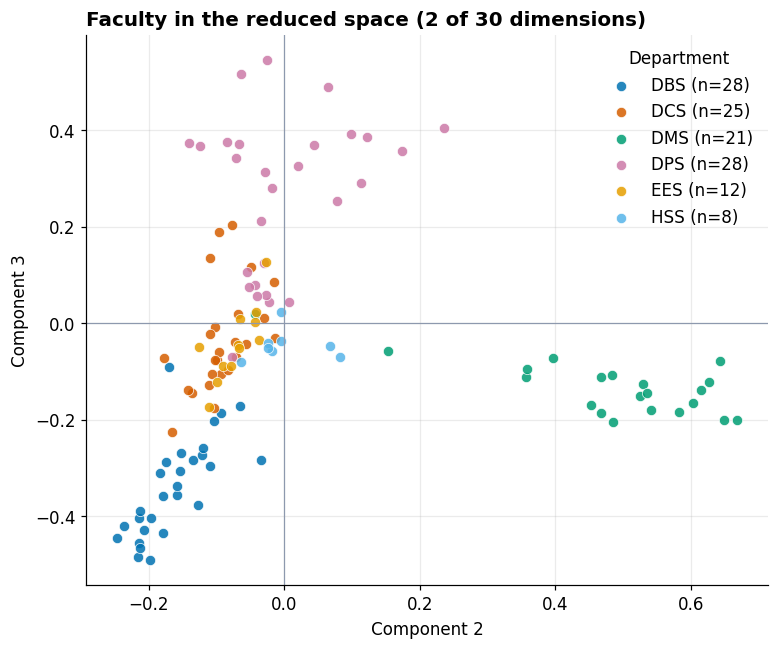

saved: /content/reports/figures/07_reduced_space_by_department.png


In [ ]:
# DAY 7 / CELL 6 -- plot departments using components 2 and 3
CODES   = sorted(rows["department_code"].unique())
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

fig, ax = plt.subplots(figsize=(8, 6.5))
for code, colour in zip(CODES, PALETTE):
    pick = ((rows["department_code"] == code) & cluster_mask).to_numpy()
    ax.scatter(X_reduced[pick, 1], X_reduced[pick, 2], s=45, alpha=0.85, color=colour, edgecolor="white", linewidth=0.5, label=f"{code} (n={int(pick.sum())})")
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlabel("Component 2"); ax.set_ylabel("Component 3")
ax.set_title(f"Faculty in the reduced space (2 of {N_COMPONENTS} dimensions)", loc="left")
ax.legend(title="Department", frameon=False, loc="best")
path = FIG_DIR / "07_reduced_space_by_department.png"
fig.savefig(path); plt.show(); print("saved:", path)

In [ ]:
# DAY 7 / CELL 6B (optional) -- find profiles sit closer to ANOTHER department's centre
labels    = rows["department_code"].to_numpy()
codes     = sorted(set(labels))
centroids = np.vstack([X_reduced[(labels == c) & cluster_mask].mean(axis=0) for c in codes])
centroids = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)
sims      = X_reduced @ centroids.T
nearest   = np.array(codes)[sims.argmax(axis=1)]
mismatch  = (nearest != labels) & cluster_mask
print(f"{int(mismatch.sum())} of {int(cluster_mask.sum())} profiles are closer to another department's centre than to their own")
print(pd.crosstab(pd.Series(labels, name="own department"), pd.Series(nearest, name="nearest centre")).to_string())
for i in np.where(mismatch)[0]:
    print(f"  {rows.loc[i, 'name']} ({labels[i]}) -> nearest centre: {nearest[i]}")

4 of 122 profiles are closer to another department's centre than to their own
nearest centre  DBS  DCS  DMS  DPS  EES  HSS
own department                              
DBS              28    0    0    0    0    0
DCS               0   23    0    2    0    0
DMS               0    0   20    0    1    0
DPS               0    0    0   27    1    0
EES               0    0    0    0   12    0
HSS               0    0    0    0    0    8
  Neeraja Sahasrabudhe (DMS) -> nearest centre: EES
  Ramesh Ramachandran (DCS) -> nearest centre: DPS
  Samir Kumar Biswas (DPS) -> nearest centre: EES
  Sajal Kumar Giri (DCS) -> nearest centre: DPS


In [ ]:
# DAY 7 / CELL 7 -- save the reduced matrix, the variance table and the fitted pipeline
import joblib
comp_cols = [f"svd_{i + 1}" for i in range(N_COMPONENTS)]
reduced_df = pd.concat([rows[["faculty_id", "name", "department_code"]],
                        pd.DataFrame(X_reduced, columns=comp_cols),
                        pd.Series(cluster_mask, name="usable_for_clustering")], axis=1)
reduced_df.to_csv(FEAT_DIR / "faculty_reduced.csv", index=False)
np.save(FEAT_DIR / "faculty_reduced.npy", X_reduced)
pd.DataFrame({"component": x, "ratio": ratio, "cumulative": cum}).to_csv(FEAT_DIR / "svd_explained_variance.csv", index=False)
joblib.dump(lsa, MODEL_DIR / "lsa_pipeline.joblib")

print("Saved:", reduced_df.shape, "-> faculty_reduced.csv")
if DRIVE.exists():
    for folder, files in [("data_features", FEAT_DIR.glob("*")), ("models", MODEL_DIR.glob("*")), ("reports_figures", FIG_DIR.glob("*.png"))]:
        (DRIVE / folder).mkdir(exist_ok=True)
        for f in files:
            shutil.copy(f, DRIVE / folder / f.name)
    print("Copied to Drive: data_features/, models/, reports_figures/")
else:
    print("Drive is not mounted -- mount it, then re-run this cell to back up.")

Saved: (122, 34) -> faculty_reduced.csv
Copied to Drive: data_features/, models/, reports_figures/


In [ ]:
# DAY 8 / CELL 1 --implement K-MEANS AND  compare with scikit-learn
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

pts   = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0], [3.5, 5.0], [4.5, 5.0]])
names = list("ABCDEF")
centroids = pts[[0, 3]].copy()
print("start centroids:", centroids.tolist())

for step in range(1, 10):
    # STEP 1 -- assign every point to its NEAREST centroid
    dist   = np.linalg.norm(pts[:, None, :] - centroids[None, :, :], axis=2)    # 6 x 2 table of distances
    labels = dist.argmin(axis=1)
    # STEP 2 -- move every centroid to the MEAN of the points assigned to it
    new_centroids = np.array([pts[labels == j].mean(axis=0) for j in range(2)])
    print(f"iteration {step}: clusters = {dict(zip(names, labels.tolist()))} -> new centroids = {new_centroids.round(3).tolist()}")
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

inertia = ((pts - centroids[labels]) ** 2).sum()
print("inertia (sum of squared distances to own centroid):", round(float(inertia), 3))

# check with sklearn using the same starting points
km = KMeans(n_clusters=2, init=pts[[0, 3]], n_init=1).fit(pts)
print("scikit-learn gives the same clusters:", bool((km.labels_ == labels).all()), "| same inertia:", bool(np.isclose(km.inertia_, inertia)))

# calculate SILHOUETTE score of point A
i       = 0
d_to_A  = np.linalg.norm(pts - pts[i], axis=1)
own     = (labels == labels[i]) & (np.arange(len(pts)) != i)
other   = labels != labels[i]
a = d_to_A[own].mean()
b = d_to_A[other].mean()
print(f"point A: a = {a:.3f}, b = {b:.3f}, silhouette = (b - a) / max(a, b) = {(b - a) / max(a, b):.3f}")
print("scikit-learn silhouette of all six points:", silhouette_samples(pts, labels).round(3).tolist())

start centroids: [[1.0, 1.0], [5.0, 7.0]]
iteration 1: clusters = {'A': 0, 'B': 0, 'C': 0, 'D': 1, 'E': 1, 'F': 1} -> new centroids = [[1.833, 2.333], [4.333, 5.667]]
iteration 2: clusters = {'A': 0, 'B': 0, 'C': 0, 'D': 1, 'E': 1, 'F': 1} -> new centroids = [[1.833, 2.333], [4.333, 5.667]]
inertia (sum of squared distances to own centroid): 10.667
scikit-learn gives the same clusters: True | same inertia: True
point A: a = 2.362, b = 5.748, silhouette = (b - a) / max(a, b) = 0.589
scikit-learn silhouette of all six points: [0.589, 0.611, -0.287, 0.596, 0.444, 0.596]


In [ ]:
# DAY 8 / CELL 2 -- load the Day 6 cluster matrix and run the health gate
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

ROOT      = Path("/content") if Path("/content").exists() else Path.cwd()
DRIVE     = Path("/content/drive/MyDrive/faculty_profile_explorer")
FEAT_DIR  = ROOT / "data" / "features";   FEAT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models";              MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

NEEDED = ["tfidf_cluster_matrix.npz", "tfidf_cluster_feature_names.csv", "tfidf_row_order.csv"]
for name in NEEDED:                                          # bring any missing file back from Drive
    if not (FEAT_DIR / name).exists() and (DRIVE / "data_features" / name).exists():
        shutil.copy(DRIVE / "data_features" / name, FEAT_DIR / name)
missing = [n for n in NEEDED if not (FEAT_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run the Day 6 one-cell rebuild first.")

X_cluster = sparse.load_npz(FEAT_DIR / "tfidf_cluster_matrix.npz").tocsr()
rows      = pd.read_csv(FEAT_DIR / "tfidf_row_order.csv")
terms     = pd.read_csv(FEAT_DIR / "tfidf_cluster_feature_names.csv")["term"].to_numpy()

words_per_row = np.diff(X_cluster.indptr)
row_len       = np.sqrt(np.asarray(X_cluster.multiply(X_cluster).sum(axis=1)).ravel())
problems = []
if not (X_cluster.shape[0] == len(rows)):          problems.append("matrix and row-order file have different numbers of rows")
if X_cluster.shape[1] != len(terms):               problems.append("feature-name file does not match the matrix")
if not np.allclose(row_len[words_per_row > 0], 1.0): problems.append("some non-empty rows do not have length 1")
if problems:
    raise RuntimeError("HEALTH GATE FAILED:\n - " + "\n - ".join(problems))
cluster_mask = words_per_row > 0                    # profiles with at least one shared word
print("HEALTH GATE PASSED |", X_cluster.shape, "| usable for clustering:", int(cluster_mask.sum()), "of", len(rows))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
BLUE, GREY, RED = "#2a6f97", "#8d99ae", "#c1121f"

HEALTH GATE PASSED | (122, 1142) | usable for clustering: 122 of 122


SILHOUETTE SCORE (rows = SVD components k, columns = number of clusters K)
K         2      3      4      5      6      7      8      9      10     11     12
k_svd                                                                             
5      0.293  0.394  0.486  0.528  0.500  0.499  0.488  0.468  0.444  0.451  0.449
8      0.182  0.262  0.310  0.360  0.397  0.413  0.430  0.438  0.433  0.415  0.410
10     0.153  0.212  0.249  0.296  0.323  0.362  0.377  0.399  0.411  0.422  0.427
15     0.103  0.143  0.169  0.203  0.224  0.241  0.251  0.260  0.285  0.297  0.314
20     0.097  0.113  0.133  0.155  0.161  0.173  0.185  0.196  0.206  0.222  0.232
30     0.052  0.075  0.090  0.104  0.103  0.117  0.130  0.123  0.133  0.133  0.148
40     0.042  0.055  0.069  0.078  0.084  0.089  0.090  0.102  0.103  0.105  0.108
50     0.034  0.051  0.059  0.065  0.073  0.070  0.068  0.078  0.080  0.086  0.089


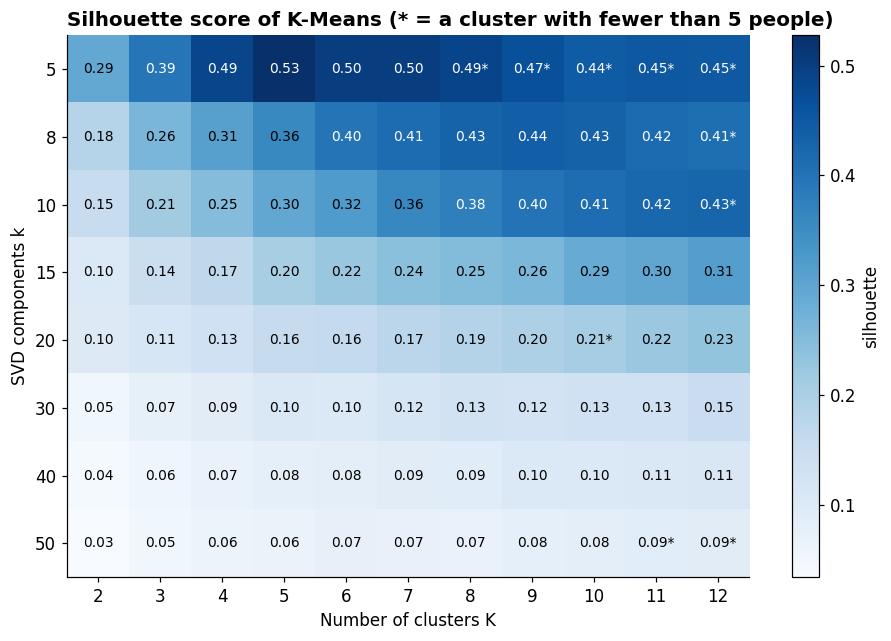

saved: /content/reports/figures/08_kmeans_silhouette_scan.png


In [ ]:
# DAY 8 / CELL 3 -- test different component and cluster counts
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_SVD_GRID = [k for k in [5, 8, 10, 15, 20, 30, 40, 50] if k < X_cluster.shape[1]]
K_GRID     = list(range(2, 13))

records = []
for k_svd in K_SVD_GRID:
    lsa = make_pipeline(TruncatedSVD(n_components=k_svd, algorithm="randomized", n_iter=7, random_state=42),
                        Normalizer(copy=False))
    Z = lsa.fit_transform(X_cluster)[cluster_mask]                      # reduced feature vectors
    for K in K_GRID:
        km    = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Z)
        sizes = np.bincount(km.labels_, minlength=K)
        records.append({"k_svd": k_svd, "K": K, "silhouette": silhouette_score(Z, km.labels_),
                        "inertia": km.inertia_, "min_size": int(sizes.min())})
scan  = pd.DataFrame(records)
pivot = scan.pivot(index="k_svd", columns="K", values="silhouette")
print("SILHOUETTE SCORE (rows = SVD components k, columns = number of clusters K)")
print(pivot.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 0.55 * len(K_SVD_GRID) + 2))
im = ax.imshow(pivot.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(K_GRID)), labels=K_GRID); ax.set_yticks(range(len(K_SVD_GRID)), labels=K_SVD_GRID)
mins = scan.pivot(index="k_svd", columns="K", values="min_size").to_numpy()
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iat[i, j]
        ax.text(j, i, f"{v:.2f}" + ("*" if mins[i, j] < 5 else ""), ha="center", va="center",
                color="white" if v > pivot.to_numpy().max() * 0.7 else "black", fontsize=9)
ax.grid(False)
ax.set_xlabel("Number of clusters K"); ax.set_ylabel("SVD components k")
ax.set_title("Silhouette score of K-Means (* = a cluster with fewer than 5 people)", loc="left")
fig.colorbar(im, ax=ax, label="silhouette")
path = FIG_DIR / "08_kmeans_silhouette_scan.png"
fig.savefig(path); plt.show(); print("saved:", path)

Best candidates: K between 4 and 10, k >= 8, no cluster smaller than 5:
 k_svd  K  silhouette  inertia  min_size
     8  9       0.438   18.625         7
     8 10       0.433   17.149         7
     8  8       0.430   21.900         7
     8  7       0.413   26.845         7
    10 10       0.411   24.528         7
    10  9       0.399   28.610         7
     8  6       0.397   32.253         7
    10  8       0.377   33.388         7

CHOSEN: k = 8 SVD components, K = 9 clusters


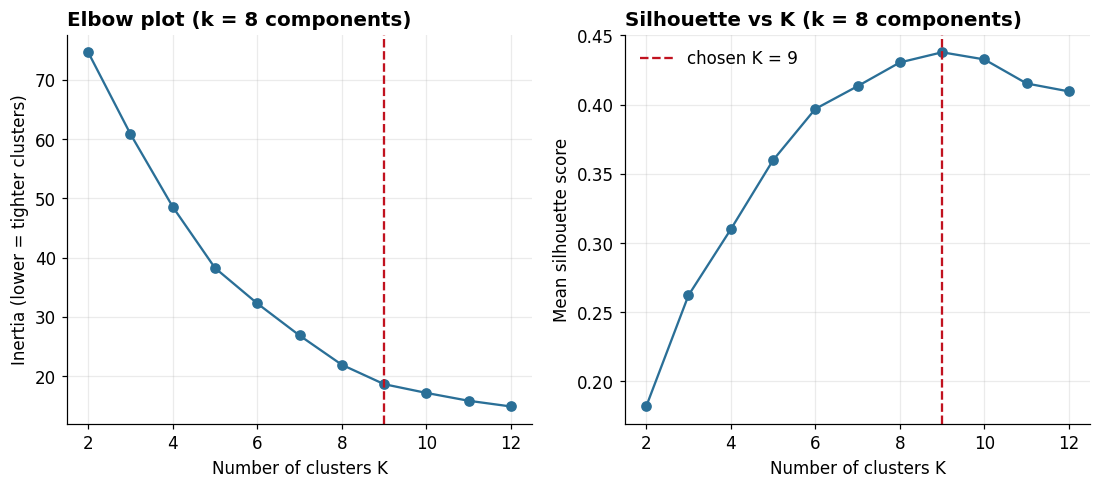

saved: /content/reports/figures/09_kmeans_elbow_silhouette.png


In [ ]:
# DAY 8 / CELL 4 -- choose the best component and cluster counts
K_RANGE     = (4, 10)      # choose a useful number of clusters
MIN_CLUSTER = 5            # reject solutions that contain a cluster of fewer than 5 people
K_SVD_MIN   = 8

cand = (scan[scan["K"].between(*K_RANGE) & (scan["min_size"] >= MIN_CLUSTER) & (scan["k_svd"] >= K_SVD_MIN)]
        .sort_values("silhouette", ascending=False))
print(f"Best candidates: K between {K_RANGE[0]} and {K_RANGE[1]}, k >= {K_SVD_MIN}, no cluster smaller than {MIN_CLUSTER}:")
print(cand.head(8).round(3).to_string(index=False))

K_SVD, K_CLUSTERS = int(cand.iloc[0]["k_svd"]), int(cand.iloc[0]["K"])

print(f"\nCHOSEN: k = {K_SVD} SVD components, K = {K_CLUSTERS} clusters")

sub = scan[scan["k_svd"] == K_SVD].sort_values("K")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.plot(sub["K"], sub["inertia"], "o-", color=BLUE)                         # elbow plot
ax1.axvline(K_CLUSTERS, color=RED, ls="--"); ax1.set_xlabel("Number of clusters K"); ax1.set_ylabel("Inertia (lower = tighter clusters)")
ax1.set_title(f"Elbow plot (k = {K_SVD} components)", loc="left")
ax2.plot(sub["K"], sub["silhouette"], "o-", color=BLUE)                      # silhouette plot
ax2.axvline(K_CLUSTERS, color=RED, ls="--", label=f"chosen K = {K_CLUSTERS}")
ax2.set_xlabel("Number of clusters K"); ax2.set_ylabel("Mean silhouette score")
ax2.set_title(f"Silhouette vs K (k = {K_SVD} components)", loc="left"); ax2.legend(frameon=False)
path = FIG_DIR / "09_kmeans_elbow_silhouette.png"
fig.savefig(path); plt.show(); print("saved:", path)

In [ ]:
# DAY 8 / CELL 5 -- fit the FINAL model with SVD, cluster with K-Means
from sklearn.metrics import silhouette_samples

lsa   = make_pipeline(TruncatedSVD(n_components=K_SVD, algorithm="randomized", n_iter=7, random_state=42),
                      Normalizer(copy=False))
Z_all = lsa.fit_transform(X_cluster)
Z     = Z_all[cluster_mask]
km    = KMeans(n_clusters=K_CLUSTERS, n_init=50, random_state=42).fit(Z)

labels = np.full(len(rows), -1);        labels[cluster_mask] = km.labels_
sil    = np.full(len(rows), np.nan);    sil[cluster_mask]    = silhouette_samples(Z, km.labels_)
dist   = np.full(len(rows), np.nan);    dist[cluster_mask]   = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)

print(f"Final model: k = {K_SVD} SVD components, K = {K_CLUSTERS} clusters")
print(f"Mean silhouette: {np.nanmean(sil):.3f} | inertia: {km.inertia_:.2f} | iterations used: {km.n_iter_}")
summary = (pd.DataFrame({"cluster": labels, "silhouette": sil, "department": rows["department_code"]})
           .query("cluster >= 0").groupby("cluster")
           .agg(size=("silhouette", "size"), mean_silhouette=("silhouette", "mean"),
                negative_silhouette=("silhouette", lambda s: int((s < 0).sum()))).round(3))
print(summary.to_string())
print("Sizes add up to:", int(summary["size"].sum()), "of", len(rows))

Final model: k = 8 SVD components, K = 9 clusters
Mean silhouette: 0.438 | inertia: 18.63 | iterations used: 5
         size  mean_silhouette  negative_silhouette
cluster                                            
0          21            0.476                    0
1          16            0.363                    1
2          10            0.574                    0
3          13            0.601                    0
4           7            0.648                    0
5          13            0.434                    0
6          17            0.385                    1
7           7            0.727                    0
8          18            0.125                    1
Sizes add up to: 122 of 122


In [ ]:
# DAY 8 / CELL 6 -- check what does each cluster represents
cent   = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)   # centroids scaled to length 1
cent_sim = pd.DataFrame(cent @ cent.T, index=[f"C{c}" for c in range(K_CLUSTERS)], columns=[f"C{c}" for c in range(K_CLUSTERS)])
print("COSINE SIMILARITY BETWEEN CLUSTER CENTROIDS (high = clusters talk about similar things):")
print(cent_sim.round(2).to_string())

overall   = np.asarray(X_cluster[cluster_mask].mean(axis=0)).ravel()
keywords  = {}
print("\nCLUSTER REPORT")
for c in range(K_CLUSTERS):
    members  = np.where(labels == c)[0]
    c_mean   = np.asarray(X_cluster[members].mean(axis=0)).ravel()
    top      = np.argsort(c_mean - overall)[::-1][:10]
    keywords[c] = [terms[j] for j in top]
    mix      = rows.loc[members, "department_code"].value_counts()
    typical  = members[np.argsort(dist[members])[:5]]
    print(f"\nCLUSTER {c}  (n = {len(members)})")
    print("  departments :", ", ".join(f"{d} {n}" for d, n in mix.items()))
    print("  keywords    :", ", ".join(keywords[c]))
    print("  most typical:", "; ".join(rows.loc[typical, "name"]))

COSINE SIMILARITY BETWEEN CLUSTER CENTROIDS (high = clusters talk about similar things):
      C0    C1    C2    C3    C4    C5    C6    C7    C8
C0  1.00  0.18  0.24  0.10  0.12  0.18  0.18  0.05  0.53
C1  0.18  1.00  0.30  0.10  0.08  0.10  0.27  0.05  0.57
C2  0.24  0.30  1.00  0.03  0.07  0.12  0.58  0.03  0.07
C3  0.10  0.10  0.03  1.00  0.04  0.11  0.05  0.29  0.08
C4  0.12  0.08  0.07  0.04  1.00  0.33  0.13  0.03  0.48
C5  0.18  0.10  0.12  0.11  0.33  1.00  0.10  0.05  0.54
C6  0.18  0.27  0.58  0.05  0.13  0.10  1.00  0.04  0.49
C7  0.05  0.05  0.03  0.29  0.03  0.05  0.04  1.00  0.10
C8  0.53  0.57  0.07  0.08  0.48  0.54  0.49  0.10  1.00

CLUSTER REPORT

CLUSTER 0  (n = 21)
  departments : DCS 20, EES 1
  keywords    : chemistry, organic, synthesis, synthetic, metal, catalysis, molecules, materials, inorganic, design
  most typical: Sanjay Mandal; Sugumar Venkataramani; Sanjay Singh; Sanchita Sengupta; Samrat Ghosh

CLUSTER 1  (n = 16)
  departments : HSS 8, EES 6, DBS 2
 

department_code  DBS  DCS  DMS  DPS  EES  HSS
cluster                                      
0                  0   20    0    0    1    0
1                  2    0    0    0    6    8
2                 10    0    0    0    0    0
3                  0    0   13    0    0    0
4                  0    0    0    7    0    0
5                  0    0    0   13    0    0
6                 16    0    0    1    0    0
7                  0    0    7    0    0    0
8                  0    5    1    7    5    0


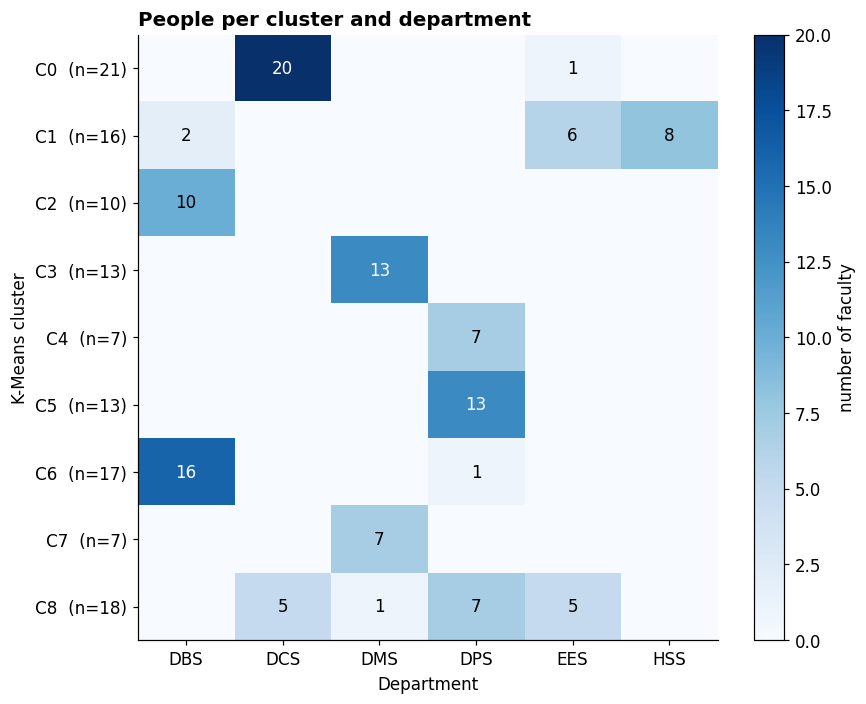

saved: /content/reports/figures/10_clusters_vs_departments.png


In [ ]:
# DAY 8 / CELL 7 -- clusters versus departments comparison
cross = pd.crosstab(pd.Series(labels[cluster_mask], name="cluster"), rows.loc[cluster_mask, "department_code"])
print(cross.to_string())

fig, ax = plt.subplots(figsize=(8.5, 0.55 * K_CLUSTERS + 2.2))
im = ax.imshow(cross.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(cross.shape[1]), labels=list(cross.columns))
ax.set_yticks(range(cross.shape[0]), labels=[f"C{c}  (n={int(cross.loc[c].sum())})" for c in cross.index])
for i in range(cross.shape[0]):
    for j in range(cross.shape[1]):
        v = int(cross.iat[i, j])
        ax.text(j, i, str(v) if v else "", ha="center", va="center", color="white" if v > cross.to_numpy().max() * 0.55 else "black")
ax.grid(False)
ax.set_xlabel("Department"); ax.set_ylabel("K-Means cluster")
ax.set_title("People per cluster and department", loc="left")
fig.colorbar(im, ax=ax, label="number of faculty")
path = FIG_DIR / "10_clusters_vs_departments.png"
fig.savefig(path); plt.show(); print("saved:", path)

In [ ]:
# DAY 8 / CELL 8 -- save cluster results and models
import joblib
CLUSTER_NAMES = {0: "Organic, inorganic and materials chemistry", 1: "Humanities, social science and human-environment studies",
                    2: "Host-pathogen interactions and immunity", 3: "Algebra, representation theory and analysis",
                    4: "Soft matter and biological/statistical physics", 5: "Quantum information, optics and gravity",
                    6: "Genetics, cell and plant biology", 7: "Algebraic geometry and topology",
                    8: "Mixed: spectroscopy, magnetism, atmospheric and observational sciences"}      # after reading the keywords, name the clusters, e.g. {0: "Algebra and number theory", 1: "Cell and molecular biology"}, then re-run this cell

names  = [CLUSTER_NAMES.get(int(c), f"Cluster {c}") if c >= 0 else "not clustered" for c in labels]
result = rows[["faculty_id", "name", "department_code"]].copy()
result["cluster"]              = labels
result["cluster_name"]         = names
result["distance_to_centroid"] = np.round(dist, 4)
result["silhouette"]           = np.round(sil, 4)
result["cluster_keywords"]     = [", ".join(keywords[c][:5]) if c >= 0 else "" for c in labels]
result.to_csv(FEAT_DIR / "faculty_clusters.csv", index=False)

pd.DataFrame({"cluster": list(keywords), "name": [CLUSTER_NAMES.get(c, f"Cluster {c}") for c in keywords],
              "size": [int((labels == c).sum()) for c in keywords],
              "keywords": [", ".join(keywords[c]) for c in keywords]}).to_csv(FEAT_DIR / "cluster_keywords.csv", index=False)
joblib.dump(lsa, MODEL_DIR / "final_lsa_pipeline.joblib")
joblib.dump(km,  MODEL_DIR / "final_kmeans.joblib")
print("Saved faculty_clusters.csv:", result.shape, "| clusters:", sorted(set(labels.tolist())))

if DRIVE.exists():
    for folder, files in [("data_features", FEAT_DIR.glob("*")), ("models", MODEL_DIR.glob("*")), ("reports_figures", FIG_DIR.glob("*.png"))]:
        (DRIVE / folder).mkdir(exist_ok=True)
        for f in files:
            shutil.copy(f, DRIVE / folder / f.name)
    print("Copied to Drive: data_features/, models/, reports_figures/")
else:
    print("Drive is not mounted -- mount it, then re-run this cell to back up.")

Saved faculty_clusters.csv: (122, 8) | clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Copied to Drive: data_features/, models/, reports_figures/


In [ ]:
# DAY 8 / CELL 9 check  borderline people and test one more cluster
idx_rows = np.where(cluster_mask)[0]

# (A) find boderline cases
d_all  = np.linalg.norm(Z[:, None, :] - km.cluster_centers_[None, :, :], axis=2)     # distance of everyone to every centroid
second = np.argsort(d_all, axis=1)[:, 1]                                              # second-nearest cluster
border = pd.DataFrame({"name": rows.loc[idx_rows, "name"].to_numpy(), "department": rows.loc[idx_rows, "department_code"].to_numpy(),
                       "cluster": km.labels_, "second_nearest": second, "silhouette": sil[idx_rows].round(3)})
print("10 MOST BORDERLINE PEOPLE")
print(border.sort_values("silhouette").head(10).to_string(index=False))

# (B) test one extra cluster
K_NEXT = K_CLUSTERS + 1
km10   = KMeans(n_clusters=K_NEXT, n_init=50, random_state=42).fit(Z)
print(f"\nMean silhouette  K={K_CLUSTERS}: {silhouette_score(Z, km.labels_):.3f} | K={K_NEXT}: {silhouette_score(Z, km10.labels_):.3f}")
print(pd.crosstab(pd.Series(km.labels_, name=f"K={K_CLUSTERS} cluster"), pd.Series(km10.labels_, name=f"K={K_NEXT} cluster")).to_string())

weak    = int(summary["mean_silhouette"].idxmin())
overall = np.asarray(X_cluster[cluster_mask].mean(axis=0)).ravel()
for j in range(K_NEXT):
    overlap = int(((km.labels_ == weak) & (km10.labels_ == j)).sum())
    if overlap >= 3:                                          # show every new cluster that received at least 3 members of the weak cluster
        members = idx_rows[km10.labels_ == j]
        c_mean  = np.asarray(X_cluster[members].mean(axis=0)).ravel()
        kw      = [terms[t] for t in np.argsort(c_mean - overall)[::-1][:8]]
        mix     = rows.loc[members, "department_code"].value_counts()
        print(f"\nK={K_NEXT} cluster {j}: gets {overlap} of the {int((km.labels_ == weak).sum())} members of old cluster {weak} | size {len(members)} | "
              + ", ".join(f"{d} {n}" for d, n in mix.items()))
        print("   keywords:", ", ".join(kw))

10 MOST BORDERLINE PEOPLE
                 name department  cluster  second_nearest  silhouette
        Baerbel Sinha        EES        8               1      -0.016
         Manjari Jain        DBS        1               6      -0.016
       Kuljeet Sandhu        DBS        6               2      -0.015
       Sudeshna Sinha        DPS        8               4       0.002
   Sabyasachi Rakshit        DCS        8               6       0.009
 Neeraja Sahasrabudhe        DMS        8               1       0.036
   Samir Kumar Biswas        DPS        6               8       0.052
Sharmila Bhattacharya        EES        8               0       0.053
  Samrat Mukhopadhyay        DBS        6               4       0.066
      Pankaj Kushwaha        DPS        8               4       0.071

Mean silhouette  K=9: 0.438 | K=10: 0.433
K=10 cluster  0   1   2   3  4  5   6  7   8   9
K=9 cluster                                     
0             1   0  20   0  0  0   0  0   0   0
1             

In [ ]:
# DAY 9 / CELL 1 -- load saved files and check results
import shutil, sqlite3, joblib
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.metrics.pairwise import cosine_similarity

ROOT      = Path("/content") if Path("/content").exists() else Path.cwd()
DRIVE     = Path("/content/drive/MyDrive/faculty_profile_explorer")
FEAT_DIR  = ROOT / "data" / "features";   FEAT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models";              MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR   = ROOT / "data" / "processed";  OUT_DIR.mkdir(parents=True, exist_ok=True)

# restore missing files from drive
FILES = {"data_features": (FEAT_DIR, ["tfidf_search_matrix.npz", "tfidf_cluster_matrix.npz", "tfidf_row_order.csv",
                                      "tfidf_cluster_feature_names.csv", "faculty_clusters.csv"]),
         "models":        (MODEL_DIR, ["tfidf_vectorizer_search.joblib", "tfidf_vectorizer_cluster.joblib",
                                       "final_lsa_pipeline.joblib", "final_kmeans.joblib"])}
for folder, (target, names) in FILES.items():
    for n in names:
        if not (target / n).exists() and (DRIVE / folder / n).exists():
            shutil.copy(DRIVE / folder / n, target / n)
missing = [n for _, (t, names) in FILES.items() for n in names if not (t / n).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Re-run Day 6 (rebuild cell) and Day 8 Cells 2-8 first.")

X_search    = sparse.load_npz(FEAT_DIR / "tfidf_search_matrix.npz").tocsr()
X_cluster   = sparse.load_npz(FEAT_DIR / "tfidf_cluster_matrix.npz").tocsr()
rows        = pd.read_csv(FEAT_DIR / "tfidf_row_order.csv")
terms       = pd.read_csv(FEAT_DIR / "tfidf_cluster_feature_names.csv")["term"].to_numpy()
vec_search  = joblib.load(MODEL_DIR / "tfidf_vectorizer_search.joblib")
vec_cluster = joblib.load(MODEL_DIR / "tfidf_vectorizer_cluster.joblib")
lsa         = joblib.load(MODEL_DIR / "final_lsa_pipeline.joblib")
km          = joblib.load(MODEL_DIR / "final_kmeans.joblib")
saved       = pd.read_csv(FEAT_DIR / "faculty_clusters.csv")
K_SVD, K    = lsa.named_steps["truncatedsvd"].n_components, km.n_clusters
print(f"Final model: k = {K_SVD} SVD components, K = {K} clusters")

# profile text lives in the database (single source of truth)
db_path = next(iter(sorted(ROOT.glob("data/**/faculty.db"))), None)
if db_path is None:
    db_path = ROOT / "data" / "db" / "faculty.db"; db_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(DRIVE / "data_db" / "faculty.db", db_path)
conn = sqlite3.connect(db_path)
db = pd.read_sql_query("SELECT faculty_id, profile_text FROM faculty", conn); conn.close()
info = rows.merge(db, on="faculty_id", how="left")
assert len(info) == len(rows) and info["profile_text"].notna().all(), "rows and database do not line up"
assert (saved["faculty_id"].to_numpy() == rows["faculty_id"].to_numpy()).all(), "saved clusters are in a different order"

# the OFFICIAL labels are the ones saved on Day 8; -1 would mean 'not clustered'
labels       = saved["cluster"].to_numpy()
cluster_mask = labels >= 0
names        = saved[cluster_mask].drop_duplicates("cluster").set_index("cluster")["cluster_name"].to_dict()

# re-create the Day 8 reduced matrix with the SAME recipe and seed, then confirm it reproduces the labels
recipe = make_pipeline(TruncatedSVD(n_components=K_SVD, algorithm="randomized", n_iter=7, random_state=42), Normalizer(copy=False))
Z_all  = recipe.fit_transform(X_cluster)
Z      = Z_all[cluster_mask]
differ = int((km.predict(Z) != labels[cluster_mask]).sum())
print(f"Clustered profiles: {int(cluster_mask.sum())} of {len(rows)} | people whose saved cluster differs from the "
      f"re-computed one: {differ} (0 expected; a few borderline people may differ if the library version changed)")

Final model: k = 8 SVD components, K = 9 clusters
Clustered profiles: 122 of 122 | people whose saved cluster differs from the re-computed one: 0 (0 expected; a few borderline people may differ if the library version changed)


Silhouette (8-D reduced space)    : 0.438
Silhouette (full TF-IDF, cosine)  : 0.060   <- the stricter, more honest number
Davies-Bouldin index (lower = better): 0.882

PER-CLUSTER QUALITY
                                           name  size  mean_sil  min_sil  n_negative top_dept  top_dept_share
cluster                                                                                                      
0        Organic, inorganic and materials chemi    21     0.476    0.117           0      DCS           0.952
1        Humanities, social science and human-e    16     0.363   -0.016           1      HSS           0.500
2        Host-pathogen interactions and immunit    10     0.574    0.187           0      DBS           1.000
3        Algebra, representation theory and ana    13     0.601    0.174           0      DMS           1.000
4        Soft matter and biological/statistical     7     0.648    0.231           0      DPS           1.000
5        Quantum information, optics and g

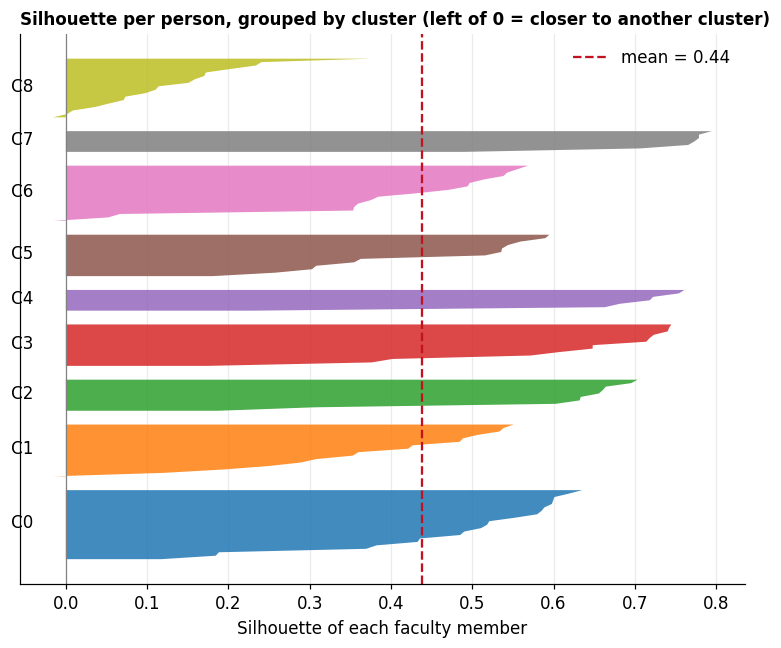

In [ ]:
# DAY 9 / CELL 2 -- EVALUATION: silhouette, per-cluster quality, sizes, stability, baseline, department check
y, Zu, Xu = labels[cluster_mask], Z, X_cluster[cluster_mask]
dept = rows.loc[cluster_mask, "department_code"].to_numpy()

# 1. headline scores
sil_reduced = silhouette_score(Zu, y)                          # the number from Day 8 (inside the 8-D space)
sil_full    = silhouette_score(Xu, y, metric="cosine")         # stricter: inside the full word space
print(f"Silhouette (8-D reduced space)    : {sil_reduced:.3f}")
print(f"Silhouette (full TF-IDF, cosine)  : {sil_full:.3f}   <- the stricter, more honest number")
print(f"Davies-Bouldin index (lower = better): {davies_bouldin_score(Zu, y):.3f}")

# 2. per-cluster quality
s = silhouette_samples(Zu, y)
tab = pd.DataFrame({"cluster": y, "sil": s, "dept": dept})
per = tab.groupby("cluster").agg(
    size=("sil", "size"), mean_sil=("sil", "mean"), min_sil=("sil", "min"),
    n_negative=("sil", lambda v: int((v < 0).sum())),
    top_dept=("dept", lambda v: v.value_counts().index[0]),
    top_dept_share=("dept", lambda v: v.value_counts().iloc[0] / len(v))).round(3)
per.insert(0, "name", [names[c][:38] for c in per.index])
print("\nPER-CLUSTER QUALITY\n" + per.to_string())

# 3. cluster-size analysis
sizes = per["size"]
print(f"\nSizes: smallest {sizes.min()} (cluster {sizes.idxmin()}), largest {sizes.max()} (cluster {sizes.idxmax()}), "
      f"largest/smallest = {sizes.max() / sizes.min():.1f}, share of people in the biggest cluster = {sizes.max() / sizes.sum():.0%}")

# 4. stability: (a) 30 single random starts, (b) 30 re-clusterings of a random 80% of the people
rng = np.random.default_rng(42)
ari_seed = [adjusted_rand_score(y, KMeans(K, n_init=1, random_state=r).fit_predict(Zu)) for r in range(30)]
ari_sub = []
for _ in range(30):
    pick = rng.choice(len(Zu), size=int(0.8 * len(Zu)), replace=False)
    again = KMeans(K, n_init=10, random_state=int(rng.integers(1_000_000))).fit_predict(Zu[pick])
    ari_sub.append(adjusted_rand_score(y[pick], again))
print(f"\nStability (ARI, 1 = identical grouping): single random starts mean {np.mean(ari_seed):.3f} (worst {np.min(ari_seed):.3f}) | "
      f"80% subsamples mean {np.mean(ari_sub):.3f} (worst {np.min(ari_sub):.3f})")

# 5. baseline: silhouette of RANDOMLY shuffled labels with the same cluster sizes
rand = [silhouette_score(Zu, rng.permutation(y)) for _ in range(200)]
print(f"Random-label baseline silhouette: mean {np.mean(rand):.3f}, highest of 200 shuffles {np.max(rand):.3f}")

# 6. sensitivity: does the same grouping appear if we keep MORE SVD components?
print("\nSame K, different number of SVD components (ARI against the final grouping):")
for k in (8, 10, 15, 20):
    Zk = make_pipeline(TruncatedSVD(k, algorithm="randomized", n_iter=7, random_state=42),
                       Normalizer(copy=False)).fit_transform(X_cluster)[cluster_mask]
    print(f"   k = {k:>2}: ARI = {adjusted_rand_score(y, KMeans(K, n_init=50, random_state=42).fit_predict(Zk)):.3f}")

# 7. does the 8-D space keep the geometry of the full word space? (compare all pairwise cosine similarities)
iu = np.triu_indices(len(Zu), k=1)
before, after = cosine_similarity(Xu)[iu], (Zu @ Zu.T)[iu]               # rows have length 1, so dot product = cosine
print(f"\nPairwise similarity, full vs {K_SVD}-D: Pearson r = {np.corrcoef(before, after)[0, 1]:.3f}, "
      f"Spearman rho = {pd.Series(before).corr(pd.Series(after), method='spearman'):.3f}")

# 8. departments as a sanity check (departments are NOT ground-truth topics)
purity = pd.crosstab(y, dept).max(axis=1).sum() / len(y)
print(f"Clusters vs departments: ARI = {adjusted_rand_score(dept, y):.3f}, NMI = {normalized_mutual_info_score(dept, y):.3f}, "
      f"purity = {purity:.1%} (purity rises automatically when K > number of departments)")

# figure: silhouette of every person, grouped by cluster
fig, ax = plt.subplots(figsize=(8.5, 6.5))
pos = 0
for c in range(K):
    v = np.sort(s[y == c]); ax.fill_betweenx(np.arange(pos, pos + len(v)), 0, v, alpha=0.85)
    ax.text(-0.04, pos + len(v) / 2, f"C{c}", ha="right", va="center"); pos += len(v) + 3
ax.axvline(sil_reduced, color="#c1121f", ls="--", label=f"mean = {sil_reduced:.2f}"); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Silhouette of each faculty member"); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("Silhouette per person, grouped by cluster (left of 0 = closer to another cluster)", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "11_silhouette_per_cluster.png", dpi=300, bbox_inches="tight"); plt.show()

In [ ]:
# DAY 9 / CELL 2B -- two extra checks: (1) shuffled-label baseline in the FULL word space, (2) which clusters survive a different SVD size?
from sklearn.metrics.pairwise import cosine_distances

# (1) the same metric as the 0.060 above, but for randomly shuffled labels (so you know what "no structure" scores here)
rng2   = np.random.default_rng(7)
D_full = cosine_distances(Xu)                                    # computed once, so 200 shuffles are fast
rand_full = [silhouette_score(D_full, rng2.permutation(y), metric="precomputed") for _ in range(200)]
print(f"Full-space silhouette: real labels {sil_full:.3f} | shuffled labels: mean {np.mean(rand_full):.3f}, highest of 200 = {np.max(rand_full):.3f}")

# (2) for each cluster: does it reappear (almost) unchanged when K-Means is run in a 10-D or 15-D SVD space?
#     Jaccard = people in both versions / people in either version (1.0 = the cluster reappears exactly)
def jaccard_table(k_other):
    Zk = make_pipeline(TruncatedSVD(k_other, algorithm="randomized", n_iter=7, random_state=42),
                       Normalizer(copy=False)).fit_transform(X_cluster)[cluster_mask]
    yk = KMeans(K, n_init=50, random_state=42).fit_predict(Zk)
    ct = pd.crosstab(y, yk).to_numpy()
    out = []
    for c in range(K):
        j = ct[c].argmax(); both = ct[c, j]
        out.append(both / (ct[c].sum() + ct[:, j].sum() - both))
    return np.round(out, 2)

robust = pd.DataFrame({"name": [names[c][:40] for c in range(K)], "size": per["size"].to_numpy(),
                       "Jaccard k=10": jaccard_table(10), "Jaccard k=15": jaccard_table(15)}, index=range(K))
print("\nDOES EACH CLUSTER SURVIVE A DIFFERENT NUMBER OF SVD COMPONENTS? (K stays 9)")
print(robust.to_string())

Full-space silhouette: real labels 0.060 | shuffled labels: mean -0.024, highest of 200 = -0.018

DOES EACH CLUSTER SURVIVE A DIFFERENT NUMBER OF SVD COMPONENTS? (K stays 9)
                                       name  size  Jaccard k=10  Jaccard k=15
0  Organic, inorganic and materials chemist    21          0.86          0.76
1  Humanities, social science and human-env    16          0.47          0.56
2   Host-pathogen interactions and immunity    10          0.38          0.91
3  Algebra, representation theory and analy    13          1.00          0.92
4  Soft matter and biological/statistical p     7          1.00          0.41
5   Quantum information, optics and gravity    13          0.92          0.39
6          Genetics, cell and plant biology    17          0.54          0.78
7           Algebraic geometry and topology     7          1.00          1.00
8  Mixed: spectroscopy, magnetism, atmosphe    18          0.59          0.24


In [ ]:
# DAY 9 / CELL 3 -- HUMAN INTERPRETATION: evidence for naming each cluster
overall = np.asarray(Xu.mean(axis=0)).ravel()                  # the average profile of everyone
dist, sil_saved = saved["distance_to_centroid"].to_numpy(), saved["silhouette"].to_numpy()
text = info["profile_text"].fillna("")

for c in range(K):
    m = np.where(labels == c)[0]
    centre = np.asarray(X_cluster[m].mean(axis=0)).ravel()
    kw  = ", ".join(terms[np.argsort(centre - overall)[::-1][:12]])           # words used MORE here than on average
    mix = ", ".join(f"{d} {n}" for d, n in rows.loc[m, "department_code"].value_counts().items())
    print(f"\n=== CLUSTER {c}  n={len(m)}  [{names[c]}] ===\n  departments: {mix}\n  keywords   : {kw}")
    for tag, who in (("typical   ", m[np.argsort(dist[m])[:3]]), ("borderline", m[np.argsort(sil_saved[m])[:2]])):
        for i in who:
            print(f"  {tag}: {rows.loc[i, 'name']} ({rows.loc[i, 'department_code']}) -> {text[i][:110]}")

# SENSITIVITY: what would K + 1 do to the MIXED clusters? (target = clusters you suspect are mixed)
TARGETS = [1]                                    # edit: e.g. [1, 8]
km_up   = KMeans(K + 1, n_init=50, random_state=42).fit(Zu)
print(f"\n\nSENSITIVITY: K = {K + 1} (silhouette {silhouette_score(Zu, km_up.labels_):.3f} vs {sil_reduced:.3f} for K = {K})")
for t in TARGETS:
    for j in range(K + 1):
        got = int(((y == t) & (km_up.labels_ == j)).sum())
        if got >= 3:
            m = np.where(cluster_mask)[0][km_up.labels_ == j]
            centre = np.asarray(X_cluster[m].mean(axis=0)).ravel()
            mix = ", ".join(f"{d} {n}" for d, n in rows.loc[m, "department_code"].value_counts().items())
            print(f"  old cluster {t} -> new cluster {j}: gets {got} of {int((y == t).sum())} | size {len(m)} | {mix}\n"
                  f"      keywords: {', '.join(terms[np.argsort(centre - overall)[::-1][:8]])}")


=== CLUSTER 0  n=21  [Organic, inorganic and materials chemistry] ===
  departments: DCS 20, EES 1
  keywords   : chemistry, organic, synthesis, synthetic, metal, catalysis, molecules, materials, inorganic, design, reaction, functional
  typical   : Sanjay Mandal (DCS) -> Organometallic/Inorganic Chemistry, Supramolecular Chemistry, Catalysis, Multifunctional Nano Materials & X-ra
  typical   : Sugumar Venkataramani (DCS) -> Physical Organic Chemistry. Key areas: Physical Organic Chemistry Synthetic Organic Chemistry Photoswitchable 
  typical   : Sanjay Singh (DCS) -> Organometallic Synthesis & Catalysis, Main Group Chemistry and Macrocyclic Chemistry. (1) Bicyclic (Alkyl)(Ami
  borderline: Arvind Kumar Shakya (EES) -> Water/Wastewater Treatment and Reuse. Multicontaminants removal by biological processes, Oxyanions and Metal/M
  borderline: Jino George (DCS) -> Physical Chemistry. Our group activities are highly interdisciplinary in nature. We study strong interactions 

=== CLUSTER

In [ ]:
# DAY 9 / CELL 4 -- your FINAL cluster names (edit after reading Cell 3), then save the final files
FINAL_NAMES = {
    0: "Organic, inorganic and materials chemistry, including catalysis",
    1: "Mixed: humanities and social sciences, hydrology/remote sensing, evolutionary ecology",
    2: "Infection, host-pathogen interactions and immunity",
    3: "Operator theory, group theory and algebra",
    4: "Soft matter, statistical and biological physics",
    5: "Quantum information, quantum thermodynamics, optics and gravity",
    6: "Genetics, genomics, cell/developmental and plant biology",
    7: "Algebraic geometry, commutative algebra and geometry",
    8: "Mixed residual group: modelling, spectroscopy, atmospheric and observational sciences",
}
assert set(FINAL_NAMES) == set(range(K)), "give every cluster a name"

final = saved.copy()
final["cluster_name"] = [FINAL_NAMES[c] if c >= 0 else "not clustered" for c in labels]
final.to_csv(OUT_DIR / "faculty_clusters_final.csv", index=False)
summary = per.drop(columns="name").copy()
summary.insert(0, "name", [FINAL_NAMES[c] for c in summary.index])
summary.to_csv(OUT_DIR / "cluster_summary.csv")
print(summary[["name", "size", "mean_sil", "top_dept", "top_dept_share"]].to_string())

                                                                                          name  size  mean_sil top_dept  top_dept_share
cluster                                                                                                                                
0                              Organic, inorganic and materials chemistry, including catalysis    21     0.476      DCS           0.952
1        Mixed: humanities and social sciences, hydrology/remote sensing, evolutionary ecology    16     0.363      HSS           0.500
2                                           Infection, host-pathogen interactions and immunity    10     0.574      DBS           1.000
3                                                    Operator theory, group theory and algebra    13     0.601      DMS           1.000
4                                              Soft matter, statistical and biological physics     7     0.648      DPS           1.000
5                              Quantum informati

In [ ]:
# DAY 9 / CELL 5 (REPLACEMENT) -- FACULTY SIMILARITY SEARCH, with a clearly labelled "related people" fallback
vocab    = {w: i for i, w in enumerate(vec_search.get_feature_names_out())}
analyzer = vec_search.build_analyzer()          # same lower-casing, stop words and tokenizer as the profiles
snippet  = info["profile_text"].fillna("").str.slice(0, 90)

def search(query, top_n=5, mode="tfidf", expand=True):
    """mode='tfidf': exact-word match over ALL words (best for rare words such as 'zebrafish').
       mode='lsa'  : match inside the 8-D topic space (coarse: finds same-topic people).
       expand=True : if fewer than top_n profiles contain the query words, fill the list with the people most similar to
                     the best match, marked 'related' (they do NOT contain the query words)."""
    tokens  = list(dict.fromkeys(analyzer(query)))
    found   = [w for w in tokens if w in vocab]
    ignored = [w for w in tokens if w not in vocab]
    print(f"\nQuery: {query!r} | mode: {mode} | words used: {found} | not in any profile: {ignored}")
    if not found:
        print("   No word of this query appears in any profile, so there is nothing to match."); return None

    q_cluster = vec_cluster.transform([query])                       # query as seen by the clustering model
    q_topic   = lsa.transform(q_cluster) if q_cluster.nnz else None
    if q_topic is not None:
        c = int(km.predict(q_topic)[0]); print(f"   Closest topic cluster: C{c} - {FINAL_NAMES[c]}")

    if mode == "tfidf":
        sims = cosine_similarity(vec_search.transform([query]), X_search).ravel()
    else:
        if q_topic is None:
            print("   No query word is in the clustering vocabulary; use mode='tfidf'."); return None
        sims = cosine_similarity(q_topic, Z_all).ravel()
    best = [int(i) for i in np.argsort(sims)[::-1][:top_n] if sims[i] > 1e-9]
    if not best:
        print("   No profile has any similarity to this query."); return None

    def line(rank, i, basis, score, shared):
        return {"rank": rank, "name": rows.loc[i, "name"], "dept": rows.loc[i, "department_code"],
                "cluster": f"C{labels[i]}" if labels[i] >= 0 else "-", "basis": basis, "score": round(float(score), 3),
                "shared_words": shared, "profile_start": snippet[i]}
    out = [line(r, i, "query words", sims[i],
                ", ".join(w for w in found if X_search[i, vocab[w]] > 0) or "(related topic only)")
           for r, i in enumerate(best, 1)]

    if mode == "tfidf" and expand and len(best) < top_n and X_cluster[best[0]].nnz:
        seed = best[0]                                               # the best exact match stands in for the query
        rel  = cosine_similarity(X_cluster[seed], X_cluster).ravel()
        rel[best] = 0                                                # do not list anyone twice
        extra = [int(i) for i in np.argsort(rel)[::-1] if rel[i] > 1e-9][: top_n - len(best)]
        start = len(out)
        out += [line(start + k, i, f"related to {rows.loc[seed, 'name']}", rel[i], "-") for k, i in enumerate(extra, 1)]
        print(f"   Only {len(best)} profile(s) contain these words, so the list is filled with people similar to {rows.loc[seed, 'name']}.")

    pd.set_option("display.max_colwidth", 90, "display.width", 240)
    print(pd.DataFrame(out).to_string(index=False))
    if any(o["basis"] != "query words" for o in out):
        print("   (score = cosine with the query for 'query words' rows, and cosine with the top match's profile for 'related' rows; do not compare them)")
    return pd.DataFrame(out)

for q in ["zebrafish regeneration", "bacterial infection", "quantum information", "algebraic geometry"]:   # edit freely
    search(q); search(q, mode="lsa")


Query: 'zebrafish regeneration' | mode: tfidf | words used: ['zebrafish', 'regeneration'] | not in any profile: []
   Only 1 profile(s) contain these words, so the list is filled with people similar to Rajesh Ramachandran.
 rank                name dept cluster                          basis  score            shared_words                                                                              profile_start
    1 Rajesh Ramachandran  DBS      C6                    query words  0.402 zebrafish, regeneration Regeneration Biology. Our research interests are to understand the molecular mechanisms un
    2  Sadhan Chandra Das  DBS      C6 related to Rajesh Ramachandran  0.211                       - Epigenetic Mechanisms in Diabetic Vascular Complications. Diabetes and metabolic disorders
    3        Sudip Mandal  DBS      C6 related to Rajesh Ramachandran  0.162                       - Molecular Cell & Developmental Biology. Mitochondrial biology is a fast growing area in ge
    4   

In [ ]:
# DAY 9 / CELL 6 -- sanity test of the search: query = a person's own 3 strongest words; do they come back in the top 5?
feat = vec_search.get_feature_names_out()
hits = tested = 0; same = []
for i in range(len(rows)):
    r = X_search.getrow(i)
    if r.nnz < 5: continue
    query = " ".join(feat[r.indices[np.argsort(r.data)[::-1][:3]]])
    top = np.argsort(cosine_similarity(vec_search.transform([query]), X_search).ravel())[::-1][:5]
    hits += int(i in top); tested += 1
    others = [j for j in top if j != i and labels[j] >= 0]
    if labels[i] >= 0 and others:
        same.append(np.mean([labels[j] == labels[i] for j in others]))
chance = float(((np.bincount(y) / len(y)) ** 2).sum())
print(f"Self-retrieval: {hits} of {tested} people appear in the top 5 for their own top-3 words")
print(f"Other top-5 results in the SAME cluster: {np.mean(same):.0%} (random pairing would give about {chance:.0%})")

Self-retrieval: 120 of 120 people appear in the top 5 for their own top-3 words
Other top-5 results in the SAME cluster: 42% (random pairing would give about 12%)


In [ ]:
if DRIVE.exists():
    for folder, files in [("data_processed", OUT_DIR.glob("*")), ("reports_figures", FIG_DIR.glob("*.png"))]:
        (DRIVE / folder).mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy(f, DRIVE / folder / f.name)
    print("Copied to Drive: data_processed/, reports_figures/")

Copied to Drive: data_processed/, reports_figures/
